<a href="https://colab.research.google.com/github/beingfroggy/muscle-fatigue-project/blob/main/EMG_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Dataset audit


Connect Google Drive and set up folders

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import re
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal

try:
    import pywt
except ImportError:
    %pip -q install PyWavelets
    import pywt

# Change this if your folder has a different name.
PROJECT_DIR = Path("/content/drive/MyDrive/EMG_Project")

EMG_ZIP = PROJECT_DIR / "sEMG_data.zip"
LABEL_ZIP = PROJECT_DIR / "self_perceived_fatigue_index.zip"

# All permanent results will be saved in Google Drive.
OUTPUT_DIR = PROJECT_DIR / "analysis_outputs"
PLOTS_DIR = OUTPUT_DIR / "plots"
TRIAL_PLOTS_DIR = PLOTS_DIR / "per_trial"
TABLES_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, PLOTS_DIR, TRIAL_PLOTS_DIR, TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("EMG ZIP exists:", EMG_ZIP.exists())
print("Fatigue-label ZIP exists:", LABEL_ZIP.exists())
print("Output folder:", OUTPUT_DIR)

if not EMG_ZIP.exists() or not LABEL_ZIP.exists():
    raise FileNotFoundError(
        "Could not find both ZIP files. Check PROJECT_DIR "
        "and the exact ZIP filenames in Google Drive."
    )

Mounted at /content/drive
Project folder: /content/drive/MyDrive/EMG_Project
EMG ZIP exists: True
Fatigue-label ZIP exists: True
Output folder: /content/drive/MyDrive/EMG_Project/analysis_outputs


Extract the dataset and find its folders

In [ ]:
WORK_DIR = Path("/content/semg_fatigue_work")
EMG_EXTRACT_DIR = WORK_DIR / "emg"
LABEL_EXTRACT_DIR = WORK_DIR / "labels"

WORK_DIR.mkdir(parents=True, exist_ok=True)

def extract_zip_if_needed(zip_path, extract_dir):
    extract_dir.mkdir(parents=True, exist_ok=True)

    # Avoid extracting the same archive again in this runtime.
    marker = extract_dir / "_extraction_complete.txt"

    if marker.exists():
        print("Already extracted:", zip_path.name)
        return

    print("Extracting:", zip_path.name)

    with zipfile.ZipFile(zip_path, "r") as archive:
        bad_file = archive.testzip()

        if bad_file is not None:
            raise RuntimeError(
                f"Corrupt file in {zip_path.name}: {bad_file}"
            )

        archive.extractall(extract_dir)

    marker.write_text("Extraction completed")
    print("Extraction complete:", extract_dir)


extract_zip_if_needed(EMG_ZIP, EMG_EXTRACT_DIR)
extract_zip_if_needed(LABEL_ZIP, LABEL_EXTRACT_DIR)


def find_subject_root(search_dir):
    """Find the folder directly containing subject_1, subject_2, etc."""
    for root, dirs, files in os.walk(search_dir):
        subject_folders = {
            d.lower() for d in dirs
        }

        if "subject_1" in subject_folders:
            return Path(root)

    raise FileNotFoundError(
        f"Could not find a folder containing subject_1 under {search_dir}"
    )


EMG_ROOT = find_subject_root(EMG_EXTRACT_DIR)
LABEL_ROOT = find_subject_root(LABEL_EXTRACT_DIR)

print("\nEMG root:", EMG_ROOT)
print("Label root:", LABEL_ROOT)

print("\nEMG subject folders:")
print(sorted(
    [p.name for p in EMG_ROOT.iterdir()
     if p.is_dir() and p.name.lower().startswith("subject_")]
))

print("\nLabel subject folders:")
print(sorted(
    [p.name for p in LABEL_ROOT.iterdir()
     if p.is_dir() and p.name.lower().startswith("subject_")]
))

Extracting: sEMG_data.zip
Extraction complete: /content/semg_fatigue_work/emg
Extracting: self_perceived_fatigue_index.zip
Extraction complete: /content/semg_fatigue_work/labels

EMG root: /content/semg_fatigue_work/emg/sEMG_data
Label root: /content/semg_fatigue_work/labels/self_perceived_fatigue_index

EMG subject folders:
['subject_1', 'subject_10', 'subject_11', 'subject_12', 'subject_13', 'subject_2', 'subject_3', 'subject_4', 'subject_5', 'subject_6', 'subject_7', 'subject_8', 'subject_9']

Label subject folders:
['subject_1', 'subject_10', 'subject_11', 'subject_12', 'subject_13', 'subject_2', 'subject_3', 'subject_4', 'subject_5', 'subject_6', 'subject_7', 'subject_8', 'subject_9']


Audit all participants and inspect the CSV format

In [ ]:
def subject_folder(root, subject_number):
    """Find a participant folder without assuming capitalization."""
    expected = f"subject_{subject_number}".lower()

    matches = [
        p for p in root.iterdir()
        if p.is_dir() and p.name.lower() == expected
    ]

    return matches[0] if matches else None


def trial_number(filename):
    """Use the last number in the filename as the trial ID."""
    numbers = re.findall(r"\d+", Path(filename).stem)

    if not numbers:
        return None

    return int(numbers[-1])


def get_csv_files(folder):
    if folder is None:
        return []

    return sorted(
        folder.glob("*.csv"),
        key=lambda p: (
            trial_number(p.name)
            if trial_number(p.name) is not None else -1
        )
    )


audit_rows = []
file_pairs = {}

for subject in range(1, 14):
    emg_folder = subject_folder(EMG_ROOT, subject)
    label_folder = subject_folder(LABEL_ROOT, subject)

    emg_files = get_csv_files(emg_folder)
    label_files = get_csv_files(label_folder)

    emg_by_trial = {}
    label_by_trial = {}

    for path in emg_files:
        tid = trial_number(path.name)
        if tid is not None:
            emg_by_trial.setdefault(tid, []).append(path)

    for path in label_files:
        tid = trial_number(path.name)
        if tid is not None:
            label_by_trial.setdefault(tid, []).append(path)

    common_trials = sorted(
        set(emg_by_trial) & set(label_by_trial)
    )

    # Pair only trials with an unambiguous matching filename ID.
    pairs = []
    for tid in common_trials:
        if len(emg_by_trial[tid]) == 1 and len(label_by_trial[tid]) == 1:
            pairs.append({
                "trial": tid,
                "emg_path": emg_by_trial[tid][0],
                "label_path": label_by_trial[tid][0],
            })

    file_pairs[subject] = pairs

    audit_rows.append({
        "subject": subject,
        "emg_folder_found": emg_folder is not None,
        "label_folder_found": label_folder is not None,
        "emg_csv_count": len(emg_files),
        "label_csv_count": len(label_files),
        "matched_trial_count": len(pairs),
        "emg_trial_ids": sorted(emg_by_trial),
        "label_trial_ids": sorted(label_by_trial),
        "unmatched_emg_trials": sorted(
            set(emg_by_trial) - set(label_by_trial)
        ),
        "unmatched_label_trials": sorted(
            set(label_by_trial) - set(emg_by_trial)
        ),
    })

audit_df = pd.DataFrame(audit_rows)

audit_df.to_csv(
    TABLES_DIR / "dataset_audit.csv",
    index=False
)

display(audit_df[[
    "subject",
    "emg_csv_count",
    "label_csv_count",
    "matched_trial_count",
    "unmatched_emg_trials",
    "unmatched_label_trials"
]])

print("\nSaved audit:", TABLES_DIR / "dataset_audit.csv")

# Inspect the first matched EMG and label files.
first_pair = next(
    (
        (subject, pair)
        for subject, pairs in file_pairs.items()
        for pair in pairs
    ),
    None
)

if first_pair is None:
    raise RuntimeError(
        "No matched EMG/label trial files were found. "
        "Inspect the folder names and filename conventions."
    )

sample_subject, sample = first_pair

sample_emg = pd.read_csv(sample["emg_path"])
sample_label = pd.read_csv(sample["label_path"])

print("\nSample participant:", sample_subject)
print("Sample trial:", sample["trial"])

print("\nEMG file:", sample["emg_path"].name)
print("EMG shape:", sample_emg.shape)
print("EMG columns:", sample_emg.columns.tolist())
display(sample_emg.head())

print("\nLabel file:", sample["label_path"].name)
print("Label shape:", sample_label.shape)
print("Label columns:", sample_label.columns.tolist())
display(sample_label.head())

,subject,emg_csv_count,label_csv_count,matched_trial_count,unmatched_emg_trials,unmatched_label_trials
0,1,12,12,12,[],[]
1,2,12,12,12,[],[]
2,3,12,12,12,[],[]
3,4,12,12,12,[],[]
4,5,12,12,12,[],[]
5,6,12,12,12,[],[]
6,7,12,12,12,[],[]
7,8,12,12,12,[],[]
8,9,12,12,12,[],[]
9,10,12,12,12,[],[]



Saved audit: /content/drive/MyDrive/EMG_Project/analysis_outputs/tables/dataset_audit.csv

Sample participant: 1
Sample trial: 1

EMG file: trial_1.csv
EMG shape: (120450, 8)
EMG columns: ['X [s]', 'R BICEPS BRACHII: EMG 1 [V]', 'X [s].1', 'R DELTOID ANTERIOR: EMG 2 [V]', 'X [s].5', 'R DELTOID MEDIUS: EMG 6 [V]', 'X [s].6', 'R DELTOID POSTERIOR: EMG 7 [V]']


,X [s],R BICEPS BRACHII: EMG 1 [V],X [s].1,R DELTOID ANTERIOR: EMG 2 [V],X [s].5,R DELTOID MEDIUS: EMG 6 [V],X [s].6,R DELTOID POSTERIOR: EMG 7 [V]
0,0.000000,-0.000004,0.000000,-0.000022,0.000000,2.182040e-06,0.000000,-0.000008
1,0.000794,-0.000007,0.000794,-0.000021,0.000794,-1.787100e-06,0.000794,-0.000011
2,0.001588,-0.000009,0.001588,-0.000022,0.001588,-6.812700e-07,0.001588,-0.000013
3,0.002382,-0.000016,0.002382,-0.000022,0.002382,1.026844e-06,0.002382,-0.000014
4,0.003176,-0.000018,0.003176,-0.000022,0.003176,1.451398e-06,0.003176,-0.000013



Label file: Trial_1.csv
Label shape: (5291, 2)
Label columns: ['time', 'label']


,time,label
0,0.00,0
1,0.02,0
2,0.04,0
3,0.06,0
4,0.08,0


#Preprocess the signal correctly

Define the channel mapping and signal-processing functions

In [ ]:
# Sampling-rate reference from the supplied dataset code.
EXPECTED_FS = 1259.0

# Initial window settings, matching the original code.
WINDOW_SECONDS = 4.0
STEP_SECONDS = 2.0

# Time and EMG columns alternate in the supplied CSV layout.
TIME_INDEX = [0, 2, 4, 6]
EMG_INDEX = [1, 3, 5, 7]

# Which of the four EMG channels to select for each trial.
PRIME_MOVER_INDEX = {
    1: 1,  2: 0,
    3: 3,  4: 2,
    5: 0,  6: 1,
    7: 2,  8: 3,
    9: 1, 10: 0,
    11: 3, 12: 2,
}

TRIAL_MUSCLE_NAMES = {
    1: "R DELTOID ANTERIOR",
    2: "L DELTOID ANTERIOR",
    3: "R DELTOID POSTERIOR",
    4: "L DELTOID POSTERIOR",
    5: "R BICEPS BRACHII",
    6: "L BICEPS BRACHII",
    7: "R DELTOID MEDIUS",
    8: "L DELTOID MEDIUS",
    9: "R DELTOID ANTERIOR C",
    10: "L DELTOID ANTERIOR C",
    11: "R DELTOID POSTERIOR C",
    12: "L DELTOID POSTERIOR C",
}


def estimate_sampling_rate(time_values):
    """Estimate Hz from the median difference between timestamps."""
    time_values = np.asarray(time_values, dtype=float)
    differences = np.diff(time_values)
    differences = differences[
        np.isfinite(differences) & (differences > 0)
    ]

    if len(differences) == 0:
        raise ValueError("Cannot estimate sampling rate from timestamps.")

    median_dt = np.median(differences)
    return 1.0 / median_dt


def filter_emg(emg, fs):
    """Clean invalid values, then apply a zero-phase bandpass filter."""
    x = np.asarray(emg, dtype=float)

    # Interpolate invalid samples instead of passing NaNs to the filter.
    x[~np.isfinite(x)] = np.nan

    if np.isnan(x).all():
        raise ValueError("The entire EMG signal is invalid.")

    x = (
        pd.Series(x)
        .interpolate(limit_direction="both")
        .to_numpy()
    )

    if not np.isfinite(x).all():
        raise ValueError("Invalid samples remain after interpolation.")

    low_hz = 20.0
    high_hz = 450.0

    # Both cutoff frequencies must be below the Nyquist frequency.
    if high_hz >= fs / 2:
        raise ValueError(
            f"Sampling rate {fs:.2f} Hz is too low for a 450 Hz cutoff."
        )

    sos = signal.butter(
        4,
        [low_hz, high_hz],
        btype="bandpass",
        fs=fs,
        output="sos",
    )

    return signal.sosfiltfilt(sos, x)


def validate_emg_file(df, file_path):
    """Check the assumed alternating time/EMG column structure."""
    if df.shape[1] < 8:
        raise ValueError(
            f"{file_path.name} has {df.shape[1]} columns; "
            "the supplied mapping requires at least 8."
        )

    if df.shape[1] != 8:
        warnings.warn(
            f"{file_path.name} has {df.shape[1]} columns, not 8. "
            "The supplied code uses the first 8; inspect extra columns."
        )

    return True


print("Channel mapping defined.")
print("Window duration:", WINDOW_SECONDS, "seconds")
print("Step size:", STEP_SECONDS, "seconds")
print("Overlap:", WINDOW_SECONDS - STEP_SECONDS, "seconds")

Channel mapping defined.
Window duration: 4.0 seconds
Step size: 2.0 seconds
Overlap: 2.0 seconds


Define the feature-extraction function

In [ ]:
def extract_features(window, fs):
    """
    Extract time-, frequency- and wavelet-domain features
    from one filtered EMG window.
    """
    x = np.asarray(window, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) < 32:
        raise ValueError("Window is too short for feature extraction.")

    # ---------- A. TIME-DOMAIN FEATURES ----------

    rms = np.sqrt(np.mean(x ** 2))
    mav = np.mean(np.abs(x))
    variance = np.var(x, ddof=1)
    std = np.std(x, ddof=1)

    differences = np.diff(x)
    waveform_length = np.sum(np.abs(differences))

    zero_crossings = np.sum(
        (x[:-1] * x[1:]) < 0
    )

    slope_sign_changes = np.sum(
        (differences[:-1] * differences[1:]) < 0
    )

    # Integrated EMG, approximated as integral of absolute amplitude.
    integrated_emg = np.sum(np.abs(x)) / fs

    features = {
        "rms": rms,
        "mav": mav,
        "variance": variance,
        "std": std,
        "waveform_length": waveform_length,
        "zero_crossings": int(zero_crossings),
        "slope_sign_changes": int(slope_sign_changes),
        "integrated_emg": integrated_emg,
    }

    # ---------- B. FREQUENCY-DOMAIN FEATURES ----------

    frequencies, psd = signal.periodogram(
        x,
        fs=fs,
        window="hann",
        detrend="constant",
        scaling="density",
    )

    # Analyse the intended EMG frequency range.
    valid = (
        (frequencies >= 20.0) &
        (frequencies <= 450.0)
    )

    f = frequencies[valid]
    p = psd[valid]

    if len(f) == 0 or np.sum(p) <= 0:
        raise ValueError("No usable spectral power in the analysis band.")

    total_power = np.trapezoid(p, f)

    # Mean frequency: average frequency weighted by spectral power.
    mean_frequency = np.sum(f * p) / np.sum(p)

    # Median frequency: frequency at which cumulative power reaches 50%.
    cumulative_power = np.cumsum(p)
    median_idx = np.searchsorted(
        cumulative_power,
        cumulative_power[-1] / 2
    )
    median_frequency = f[min(median_idx, len(f) - 1)]

    probabilities = p / np.sum(p)
    nonzero_probabilities = probabilities[probabilities > 0]

    spectral_entropy = -np.sum(
        nonzero_probabilities * np.log2(nonzero_probabilities)
    )

    if len(probabilities) > 1:
        spectral_entropy /= np.log2(len(probabilities))

    features.update({
        "mean_frequency": mean_frequency,
        "median_frequency": median_frequency,
        "spectral_power": total_power,
        "spectral_entropy": spectral_entropy,
    })

    # ---------- C. WAVELET-DOMAIN FEATURES ----------

    wavelet = pywt.Wavelet("db4")
    max_level = pywt.dwt_max_level(len(x), wavelet.dec_len)
    level = min(4, max_level)

    if level < 1:
        raise ValueError("Window is too short for wavelet decomposition.")

    coefficients = pywt.wavedec(
        x,
        wavelet=wavelet,
        level=level,
    )

    # wavedec returns [approximation, detail at highest level, ...].
    energies = np.array([
        np.sum(c ** 2) for c in coefficients
    ], dtype=float)

    names = (
        [f"wavelet_A{level}"] +
        [f"wavelet_D{i}" for i in range(level, 0, -1)]
    )

    for name, energy in zip(names, energies):
        features[f"{name}_energy"] = energy

    total_wavelet_energy = energies.sum()

    if total_wavelet_energy > 0:
        energy_probabilities = energies / total_wavelet_energy
        energy_probabilities = energy_probabilities[
            energy_probabilities > 0
        ]

        wavelet_entropy = -np.sum(
            energy_probabilities * np.log2(energy_probabilities)
        )

        if len(energies) > 1:
            wavelet_entropy /= np.log2(len(energies))
    else:
        wavelet_entropy = 0.0

    features["wavelet_entropy"] = wavelet_entropy

    return features


print("Feature extraction function defined.")

Feature extraction function defined.


#Build the master feature dataset

Process all participants and create the feature table

In [ ]:
def load_numeric_column(df, column_index):
    """Convert a CSV column to numeric values."""
    return pd.to_numeric(
        df.iloc[:, column_index],
        errors="coerce"
    ).to_numpy(dtype=float)


def label_window(label_times, label_values, start_time, end_time):
    """
    Assign the majority fatigue label within a window.
    Also return label purity and whether labels were mixed.
    """
    inside = (
        np.isfinite(label_times) &
        np.isfinite(label_values) &
        (label_times >= start_time) &
        (label_times <= end_time)
    )

    values = label_values[inside].astype(int)

    if len(values) == 0:
        # Fallback if no rating timestamp falls inside the window.
        valid = (
            np.isfinite(label_times) &
            np.isfinite(label_values)
        )

        if not valid.any():
            return None, np.nan, True

        valid_times = label_times[valid]
        valid_values = label_values[valid].astype(int)

        nearest = np.argmin(
            np.abs(valid_times - (start_time + end_time) / 2)
        )

        return int(valid_values[nearest]), np.nan, True

    counts = pd.Series(values).value_counts()
    highest_count = counts.max()
    tied_labels = sorted(
        counts[counts == highest_count].index.tolist()
    )

    # Use the smaller label for a tie, and record purity separately.
    assigned_label = int(tied_labels[0])
    purity = float(highest_count / len(values))
    mixed = len(np.unique(values)) > 1

    return assigned_label, purity, mixed


feature_rows = []
processing_errors = []
sampling_rate_rows = []

for subject, pairs in file_pairs.items():

    for pair in pairs:
        trial = pair["trial"]
        emg_path = pair["emg_path"]
        label_path = pair["label_path"]

        try:
            # Read source files.
            emg_df = pd.read_csv(emg_path)
            label_df = pd.read_csv(label_path)

            validate_emg_file(emg_df, emg_path)

            if trial not in PRIME_MOVER_INDEX:
                raise ValueError(
                    f"No prime-mover mapping for trial {trial}"
                )

            channel = PRIME_MOVER_INDEX[trial]

            time_col = TIME_INDEX[channel]
            emg_col = EMG_INDEX[channel]

            raw_time = load_numeric_column(emg_df, time_col)
            raw_emg = load_numeric_column(emg_df, emg_col)

            # Keep rows with valid timestamps, then interpolate invalid
            # signal values during filtering.
            valid_time = np.isfinite(raw_time)
            raw_time = raw_time[valid_time]
            raw_emg = raw_emg[valid_time]

            if len(raw_time) < 100:
                raise ValueError("Too few valid EMG timestamps.")

            # Ensure time is increasing and remove duplicate timestamps.
            order = np.argsort(raw_time)
            raw_time = raw_time[order]
            raw_emg = raw_emg[order]

            unique_time, unique_indices = np.unique(
                raw_time, return_index=True
            )
            raw_time = unique_time
            raw_emg = raw_emg[unique_indices]

            fs = estimate_sampling_rate(raw_time)

            sampling_rate_rows.append({
                "subject": subject,
                "trial": trial,
                "estimated_fs_hz": fs,
                "expected_fs_hz": EXPECTED_FS,
                "difference_hz": fs - EXPECTED_FS,
            })

            if not 800 <= fs <= 1600:
                warnings.warn(
                    f"Unexpected sampling rate: Subject {subject}, "
                    f"trial {trial}: {fs:.2f} Hz. Inspect timestamps."
                )

            filtered_emg = filter_emg(raw_emg, fs)

            # Read the first two label columns as timestamp and class.
            label_times = load_numeric_column(label_df, 0)
            label_values = load_numeric_column(label_df, 1)

            valid_labels = (
                np.isfinite(label_times) &
                np.isfinite(label_values)
            )

            label_times = label_times[valid_labels]
            label_values = label_values[valid_labels]

            if len(label_times) == 0:
                raise ValueError("No valid fatigue labels.")

            if not np.all(
                np.isclose(label_values, np.round(label_values))
            ):
                raise ValueError("Fatigue labels are not integers.")

            label_values = np.round(label_values).astype(int)

            observed_classes = set(np.unique(label_values))
            if not observed_classes.issubset({0, 1, 2}):
                raise ValueError(
                    f"Unexpected fatigue labels: {observed_classes}"
                )

            label_order = np.argsort(label_times)
            label_times = label_times[label_order]
            label_values = label_values[label_order]

            window_samples = int(round(WINDOW_SECONDS * fs))
            step_samples = int(round(STEP_SECONDS * fs))

            if len(filtered_emg) < window_samples:
                raise ValueError(
                    "Recording is shorter than one complete window."
                )

            number_of_windows = (
                1 +
                (len(filtered_emg) - window_samples) // step_samples
            )

            for window_index in range(number_of_windows):
                start_idx = window_index * step_samples
                end_idx = start_idx + window_samples

                window = filtered_emg[start_idx:end_idx]
                window_times = raw_time[start_idx:end_idx]

                start_time = float(window_times[0])
                end_time = float(window_times[-1])
                center_time = float(
                    (start_time + end_time) / 2
                )

                label, purity, mixed = label_window(
                    label_times,
                    label_values,
                    start_time,
                    end_time,
                )

                if label is None:
                    continue

                features = extract_features(window, fs)

                row = {
                    "subject": subject,
                    "trial": trial,
                    "muscle": TRIAL_MUSCLE_NAMES[trial],
                    "channel_index_within_file": channel,
                    "window_index": window_index,
                    "window_start_s": start_time,
                    "window_end_s": end_time,
                    "window_center_s": center_time,
                    "sampling_rate_hz": fs,
                    "fatigue_label": label,
                    "label_purity": purity,
                    "mixed_label_window": mixed,
                }

                row.update(features)
                feature_rows.append(row)

        except Exception as error:
            processing_errors.append({
                "subject": subject,
                "trial": trial,
                "emg_file": emg_path.name,
                "label_file": label_path.name,
                "error": str(error),
            })

# Convert collected rows to dataframes.
feature_df = pd.DataFrame(feature_rows)
sampling_rate_df = pd.DataFrame(sampling_rate_rows)
errors_df = pd.DataFrame(processing_errors)

if feature_df.empty:
    raise RuntimeError(
        "No feature rows were created. Check the audit and errors."
    )

# Save everything permanently to Google Drive.
feature_path = TABLES_DIR / "semg_feature_dataset.csv"
sampling_path = TABLES_DIR / "sampling_rate_audit.csv"
errors_path = TABLES_DIR / "processing_errors.csv"

feature_df.to_csv(feature_path, index=False)
sampling_rate_df.to_csv(sampling_path, index=False)
errors_df.to_csv(errors_path, index=False)

print("Feature table created.")
print("Rows:", len(feature_df))
print("Columns:", len(feature_df.columns))
print("Subjects:", feature_df["subject"].nunique())
print("Trials:", feature_df[["subject", "trial"]].drop_duplicates().shape[0])

print("\nSaved feature table:", feature_path)
print("Saved sampling-rate audit:", sampling_path)
print("Saved processing errors:", errors_path)

print("\nProcessing errors:", len(errors_df))
display(errors_df.head(20))

Feature table created.
Rows: 23760
Columns: 30
Subjects: 13
Trials: 156

Saved feature table: /content/drive/MyDrive/EMG_Project/analysis_outputs/tables/semg_feature_dataset.csv
Saved sampling-rate audit: /content/drive/MyDrive/EMG_Project/analysis_outputs/tables/sampling_rate_audit.csv
Saved processing errors: /content/drive/MyDrive/EMG_Project/analysis_outputs/tables/processing_errors.csv

Processing errors: 0


""


Generate and save the diagnostic plots

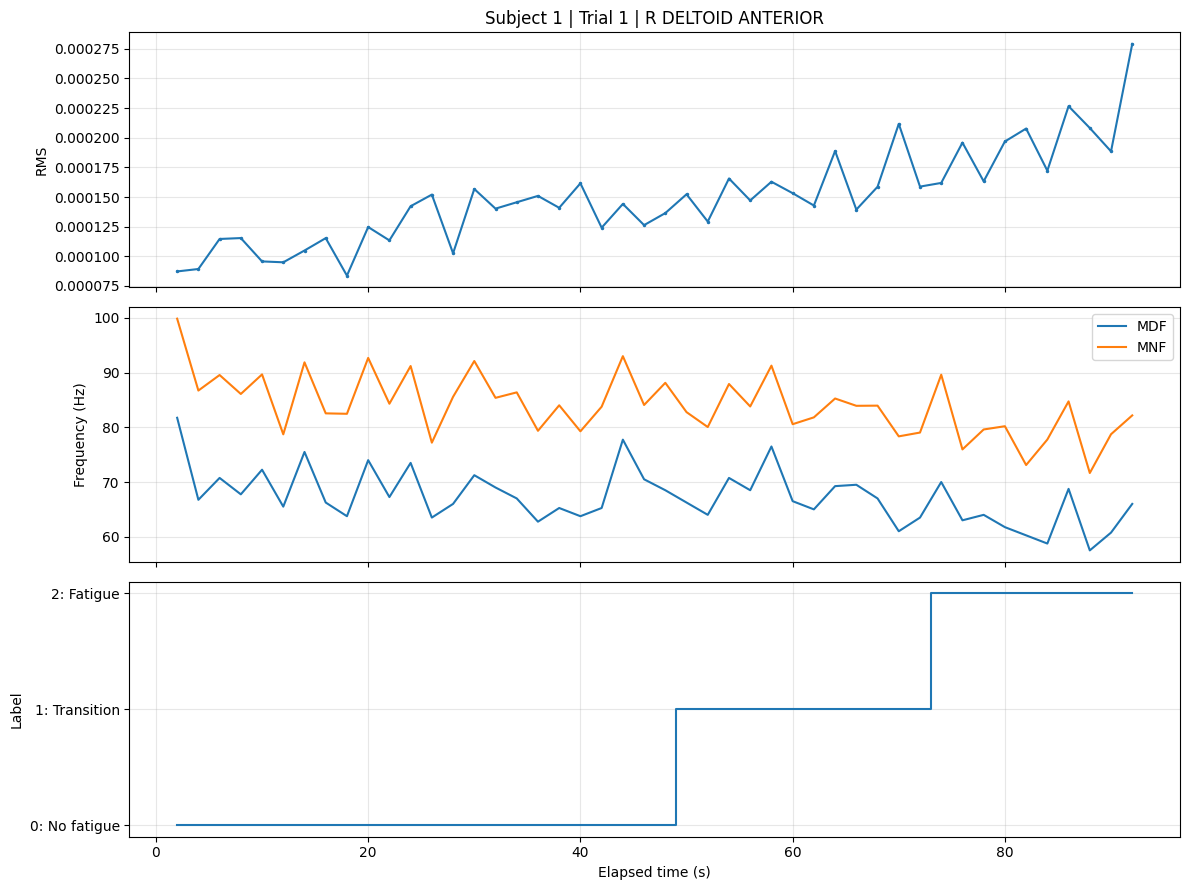

Saved 156 trial plots to:
/content/drive/MyDrive/EMG_Project/analysis_outputs/plots/per_trial


In [ ]:
saved_plots = 0

for (subject, trial), group in feature_df.groupby(
    ["subject", "trial"], sort=True
):
    group = group.sort_values("window_center_s")

    fig, axes = plt.subplots(
        3, 1,
        figsize=(12, 9),
        sharex=True
    )

    t = group["window_center_s"]

    # Plot 1: Signal magnitude.
    axes[0].plot(t, group["rms"], marker=".", markersize=3)
    axes[0].set_ylabel("RMS")
    axes[0].set_title(
        f"Subject {subject} | Trial {trial} | "
        f"{TRIAL_MUSCLE_NAMES[trial]}"
    )
    axes[0].grid(True, alpha=0.3)

    # Plot 2: Frequency features.
    axes[1].plot(t, group["median_frequency"], label="MDF")
    axes[1].plot(t, group["mean_frequency"], label="MNF")
    axes[1].set_ylabel("Frequency (Hz)")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # Plot 3: Fatigue labels.
    axes[2].step(
        t,
        group["fatigue_label"],
        where="mid"
    )
    axes[2].set_yticks([0, 1, 2])
    axes[2].set_yticklabels([
        "0: No fatigue",
        "1: Transition",
        "2: Fatigue"
    ])
    axes[2].set_xlabel("Elapsed time (s)")
    axes[2].set_ylabel("Label")
    axes[2].grid(True, alpha=0.3)

    fig.tight_layout()

    plot_path = (
        TRIAL_PLOTS_DIR /
        f"subject_{subject:02d}_trial_{trial:02d}.png"
    )

    fig.savefig(plot_path, dpi=150, bbox_inches="tight")

    # Display only the first plot to avoid flooding the notebook.
    if saved_plots == 0:
        plt.show()

    plt.close(fig)
    saved_plots += 1

print(f"Saved {saved_plots} trial plots to:")
print(TRIAL_PLOTS_DIR)

Inspect the completed dataset

MASTER FEATURE TABLE
Total windows: 23760
Participants: 13
Participant-trial combinations: 156
Unique fatigue classes: [np.int64(0), np.int64(1), np.int64(2)]

Windows per participant:


,subject,number_of_windows
0,1,1963
1,2,1710
2,3,2294
3,4,1156
4,5,1364
5,6,1544
6,7,1218
7,8,2510
8,9,2293
9,10,1294



Fatigue-label distribution:


,fatigue_label,window_count,percentage
0,0,7991,33.63
1,1,8268,34.80
2,2,7501,31.57


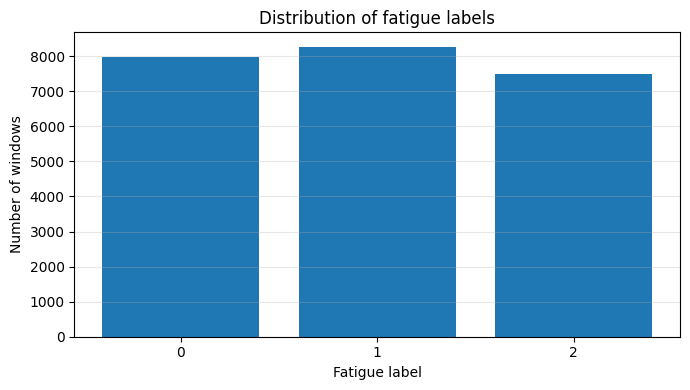

Saved label distribution plot: /content/drive/MyDrive/EMG_Project/analysis_outputs/plots/fatigue_label_distribution.png

Feature table preview:


,subject,trial,muscle,channel_index_within_file,window_index,window_start_s,window_end_s,window_center_s,sampling_rate_hz,fatigue_label,...,mean_frequency,median_frequency,spectral_power,spectral_entropy,wavelet_A4_energy,wavelet_D4_energy,wavelet_D3_energy,wavelet_D2_energy,wavelet_D1_energy,wavelet_entropy
0,1,1,R DELTOID ANTERIOR,1,0,0.000000,3.999174,1.999587,1259.26,0,...,99.873179,81.750649,5.525966e-09,0.837680,0.000003,0.000018,0.000011,0.000005,5.944339e-07,0.778177
1,1,1,R DELTOID ANTERIOR,1,1,2.000381,5.999555,3.999968,1259.26,0,...,86.728093,66.750530,9.962497e-09,0.818354,0.000006,0.000016,0.000012,0.000005,6.127247e-07,0.830214
2,1,1,R DELTOID ANTERIOR,1,2,4.000762,7.999936,6.000349,1259.26,0,...,89.568094,70.750562,5.594193e-09,0.814777,0.000008,0.000029,0.000021,0.000008,7.752468e-07,0.796803
3,1,1,R DELTOID ANTERIOR,1,3,6.001144,10.000318,8.000731,1259.26,0,...,86.104030,67.750538,1.769767e-08,0.801770,0.000010,0.000029,0.000019,0.000009,8.413707e-07,0.821132
4,1,1,R DELTOID ANTERIOR,1,4,8.001525,12.000699,10.001112,1259.26,0,...,89.679766,72.250574,4.263013e-09,0.822958,0.000008,0.000021,0.000013,0.000005,5.172101e-07,0.811833



Feature table information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23760 entries, 0 to 23759
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   subject                    23760 non-null  int64  
 1   trial                      23760 non-null  int64  
 2   muscle                     23760 non-null  object 
 3   channel_index_within_file  23760 non-null  int64  
 4   window_index               23760 non-null  int64  
 5   window_start_s             23760 non-null  float64
 6   window_end_s               23760 non-null  float64
 7   window_center_s            23760 non-null  float64
 8   sampling_rate_hz           23760 non-null  float64
 9   fatigue_label              23760 non-null  int64  
 10  label_purity               23760 non-null  float64
 11  mixed_label_window         23760 non-null  bool   
 12  rms                        23760 non-null  float64
 13  mav               

In [ ]:
print("MASTER FEATURE TABLE")
print("=" * 50)

print("Total windows:", len(feature_df))
print("Participants:", feature_df["subject"].nunique())
print("Participant-trial combinations:",
      feature_df[["subject", "trial"]].drop_duplicates().shape[0])
print("Unique fatigue classes:",
      sorted(feature_df["fatigue_label"].unique()))

print("\nWindows per participant:")
display(
    feature_df.groupby("subject")
    .size()
    .rename("number_of_windows")
    .reset_index()
)

print("\nFatigue-label distribution:")
label_counts = (
    feature_df["fatigue_label"]
    .value_counts()
    .reindex([0, 1, 2], fill_value=0)
    .rename_axis("fatigue_label")
    .reset_index(name="window_count")
)

label_counts["percentage"] = (
    label_counts["window_count"] /
    label_counts["window_count"].sum() * 100
).round(2)

display(label_counts)

# Save the label distribution plot to Drive.
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    label_counts["fatigue_label"].astype(str),
    label_counts["window_count"]
)

ax.set_xlabel("Fatigue label")
ax.set_ylabel("Number of windows")
ax.set_title("Distribution of fatigue labels")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

label_plot_path = PLOTS_DIR / "fatigue_label_distribution.png"
fig.savefig(label_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved label distribution plot:", label_plot_path)

print("\nFeature table preview:")
display(feature_df.head())

print("\nFeature table information:")
feature_df.info()

print("\nAll permanent results are under:")
print(OUTPUT_DIR)

#Validate labels and inspect fatigue patterns

Validate the dataset before training a model

In [ ]:

# CELL 9: DATA QUALITY AND TIMESTAMP AUDIT

from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/EMG_Project")
OUTPUT_DIR = PROJECT_DIR / "analysis_outputs"
TABLES_DIR = OUTPUT_DIR / "tables"

feature_df = pd.read_csv(
    TABLES_DIR / "semg_feature_dataset.csv"
)

print("FEATURE TABLE QUALITY")
print("=" * 50)
print("Rows:", len(feature_df))
print("Missing values:", int(feature_df.isna().sum().sum()))
print("Duplicate rows:", int(feature_df.duplicated().sum()))
print("Labels:", sorted(feature_df["fatigue_label"].unique()))

numeric_cols = feature_df.select_dtypes(include=np.number).columns
numeric_values = feature_df[numeric_cols].to_numpy()

print("Infinite numeric values:", int(np.isinf(numeric_values).sum()))

print("\nLABEL ALIGNMENT")
print("=" * 50)
print(
    "Mixed-label windows:",
    int(feature_df["mixed_label_window"].sum()),
    f"({feature_df['mixed_label_window'].mean() * 100:.2f}%)"
)
print(
    "Mean label purity:",
    round(feature_df["label_purity"].mean(), 3)
)
print(
    "Windows with purity below 0.80:",
    int((feature_df["label_purity"] < 0.80).sum())
)

print("\nSAMPLING-RATE AUDIT")
print("=" * 50)
rate_audit = pd.read_csv(
    TABLES_DIR / "sampling_rate_audit.csv"
)
display(rate_audit.head(10))
print("Sampling-rate audit shape:", rate_audit.shape)

# Compare EMG and label time ranges for every matched trial.
# Uses helper functions created in Cell 3.

duration_records = []

for subject in range(1, 14):
    emg_folder = subject_folder(EMG_ROOT, subject)
    label_folder = subject_folder(LABEL_ROOT, subject)

    emg_files = {
        trial_number(p.name): p
        for p in get_csv_files(emg_folder)
    }
    label_files = {
        trial_number(p.name): p
        for p in get_csv_files(label_folder)
    }

    for trial in sorted(set(emg_files) & set(label_files)):
        try:
            emg = pd.read_csv(emg_files[trial])
            labels = pd.read_csv(label_files[trial])

            emg_time = pd.to_numeric(
                emg.iloc[:, 0], errors="coerce"
            ).dropna()

            label_time = pd.to_numeric(
                labels.iloc[:, 0], errors="coerce"
            ).dropna()

            emg_duration = emg_time.max() - emg_time.min()
            label_duration = label_time.max() - label_time.min()

            duration_records.append({
                "subject": subject,
                "trial": trial,
                "emg_duration_s": emg_duration,
                "label_duration_s": label_duration,
                "duration_difference_s": (
                    label_duration - emg_duration
                )
            })

        except Exception as e:
            print(
                f"Could not audit subject {subject}, "
                f"trial {trial}: {e}"
            )

duration_df = pd.DataFrame(duration_records)
duration_path = TABLES_DIR / "duration_audit.csv"
duration_df.to_csv(duration_path, index=False)

print("\nRECORDING DURATION COMPARISON")
print("=" * 50)
display(duration_df.head(10))

print(
    "Trials with label duration longer than EMG:",
    int((duration_df["duration_difference_s"] > 1).sum())
)
print(
    "Trials with EMG duration longer than labels:",
    int((duration_df["duration_difference_s"] < -1).sum())
)
print(
    "Saved duration audit to:",
    duration_path
)


FEATURE TABLE QUALITY
Rows: 23760
Missing values: 0
Duplicate rows: 0
Labels: [np.int64(0), np.int64(1), np.int64(2)]
Infinite numeric values: 0

LABEL ALIGNMENT
Mixed-label windows: 606 (2.55%)
Mean label purity: 0.994
Windows with purity below 0.80: 358

SAMPLING-RATE AUDIT


,subject,trial,estimated_fs_hz,expected_fs_hz,difference_hz
0,1,1,1259.26,1259.0,0.26
1,1,2,1259.26,1259.0,0.26
2,1,3,1259.26,1259.0,0.26
3,1,4,1259.26,1259.0,0.26
4,1,5,1259.26,1259.0,0.26
5,1,6,1259.26,1259.0,0.26
6,1,7,1259.26,1259.0,0.26
7,1,8,1259.26,1259.0,0.26
8,1,9,1259.26,1259.0,0.26
9,1,10,1259.26,1259.0,0.26


Sampling-rate audit shape: (156, 5)

RECORDING DURATION COMPARISON


,subject,trial,emg_duration_s,label_duration_s,duration_difference_s
0,1,1,95.650620,105.80000,10.149380
1,1,2,111.992758,115.04000,3.047242
2,1,3,812.960786,817.52097,4.560184
3,1,4,699.923765,702.50001,2.576245
4,1,5,178.854248,181.92000,3.065752
5,1,6,211.334435,214.20100,2.866565
6,1,7,113.766815,116.57900,2.812185
7,1,8,119.439989,122.20000,2.760011
8,1,9,351.935264,354.56001,2.624746
9,1,10,570.852723,573.73997,2.887247


Trials with label duration longer than EMG: 133
Trials with EMG duration longer than labels: 0
Saved duration audit to: /content/drive/MyDrive/EMG_Project/analysis_outputs/tables/duration_audit.csv


See whether the EMG features change with reported fatigue

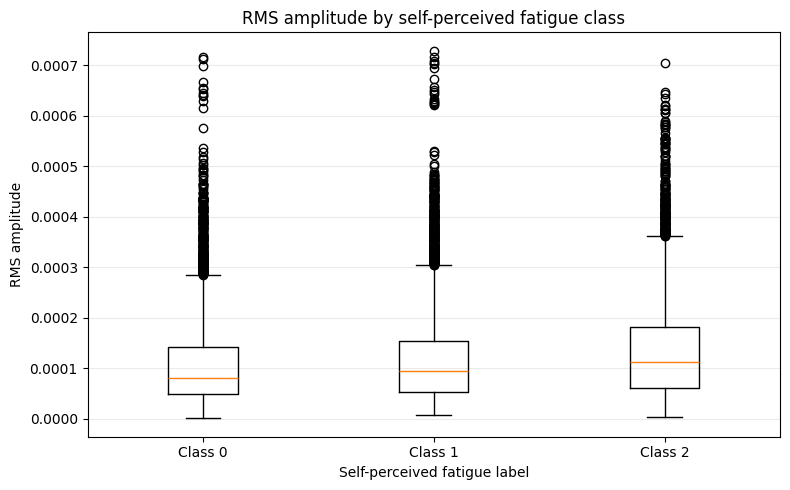

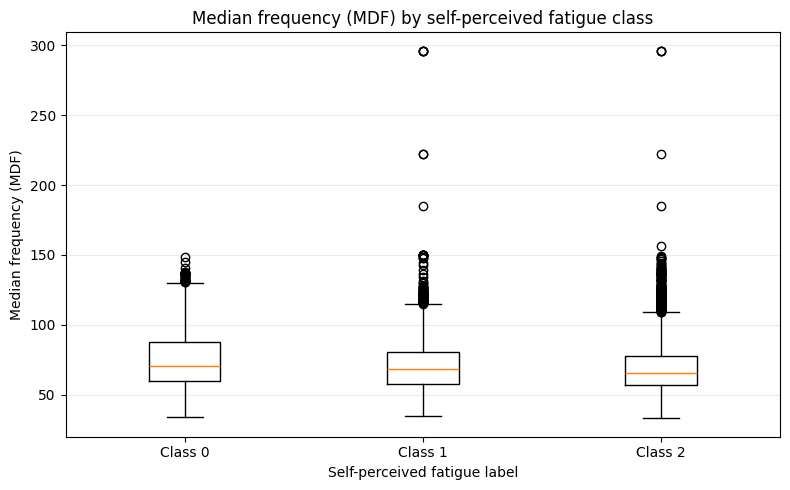

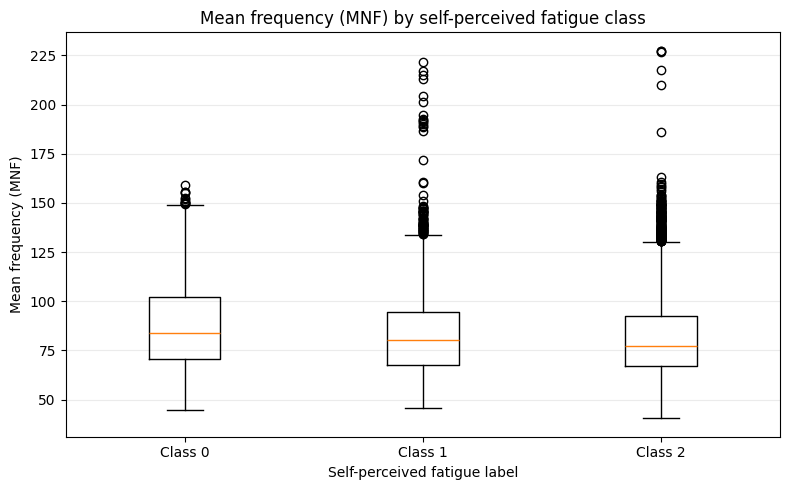

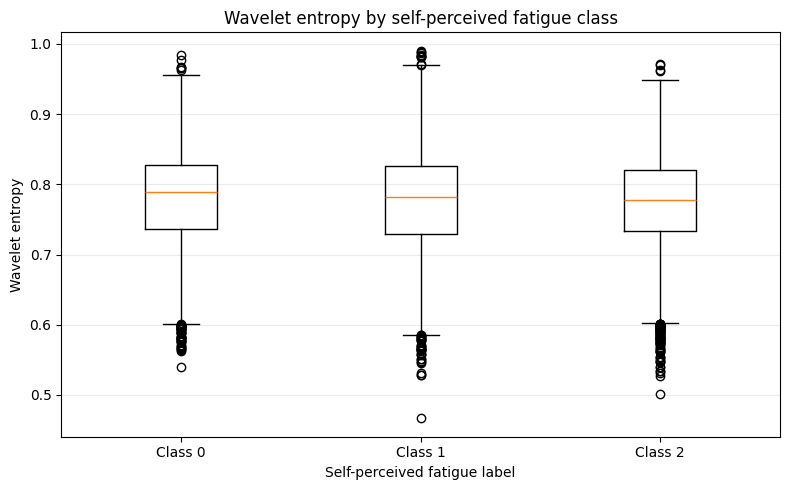

Saved feature plots to: /content/drive/MyDrive/EMG_Project/analysis_outputs/plots
Saved summary statistics.


In [ ]:

# CELL 10: EXPLORE FEATURES BY FATIGUE CLASS

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

PLOTS_DIR = Path(
    "/content/drive/MyDrive/EMG_Project/"
    "analysis_outputs/plots"
)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Start with four interpretable features.
features_to_plot = [
    ("rms", "RMS amplitude"),
    ("median_frequency", "Median frequency (MDF)"),
    ("mean_frequency", "Mean frequency (MNF)"),
    ("wavelet_entropy", "Wavelet entropy")
]

# Save summary statistics for the report.
summary = (
    feature_df.groupby("fatigue_label")[
        [feature for feature, _ in features_to_plot]
    ]
    .agg(["median", "mean", "std"])
)

summary.to_csv(
    PLOTS_DIR.parent / "tables" / "feature_summary_by_label.csv"
)

for feature, title in features_to_plot:
    fig, ax = plt.subplots(figsize=(8, 5))

    values = [
        feature_df.loc[
            feature_df["fatigue_label"] == label, feature
        ].dropna().values
        for label in [0, 1, 2]
    ]

    ax.boxplot(values, tick_labels=[
        "Class 0", "Class 1", "Class 2"
    ])
    ax.set_title(f"{title} by self-perceived fatigue class")
    ax.set_xlabel("Self-perceived fatigue label")
    ax.set_ylabel(title)
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        PLOTS_DIR / f"{feature}_by_fatigue_class.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

print("Saved feature plots to:", PLOTS_DIR)
print("Saved summary statistics.")


INSPECT EMG AND FATIGUE-LABEL TIMELINES

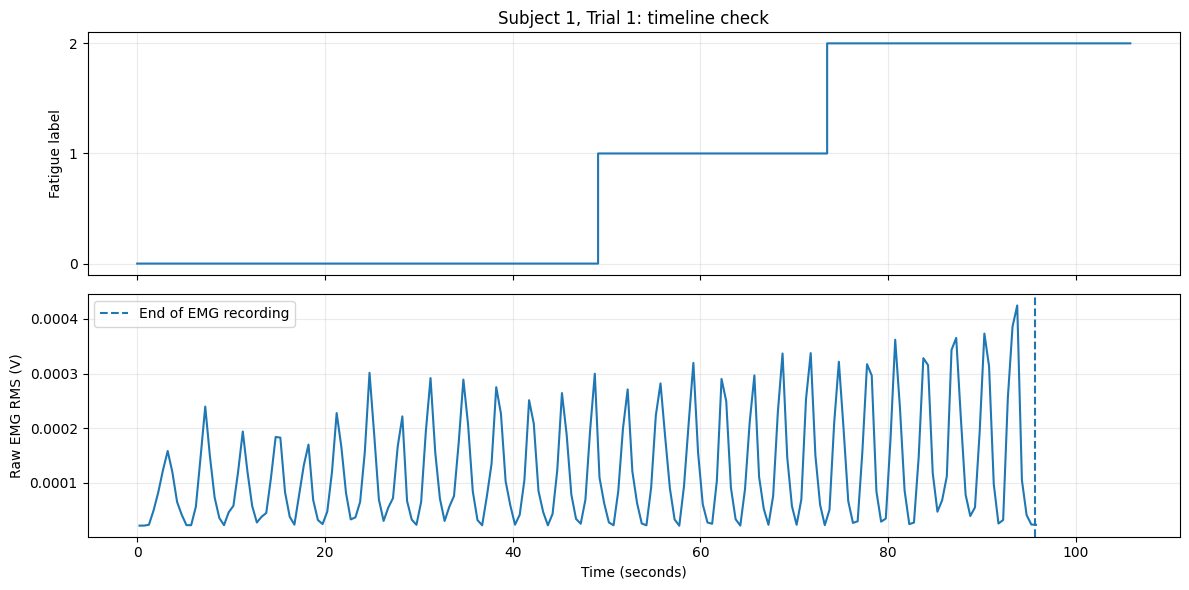


Subject 1, trial 1
EMG time range: 0.000–95.651 s
Label time range: 0.000–105.800 s
First label transitions (seconds): [49.1 73.5]
Saved: /content/drive/MyDrive/EMG_Project/analysis_outputs/plots/timeline_subject_1_trial_1.png


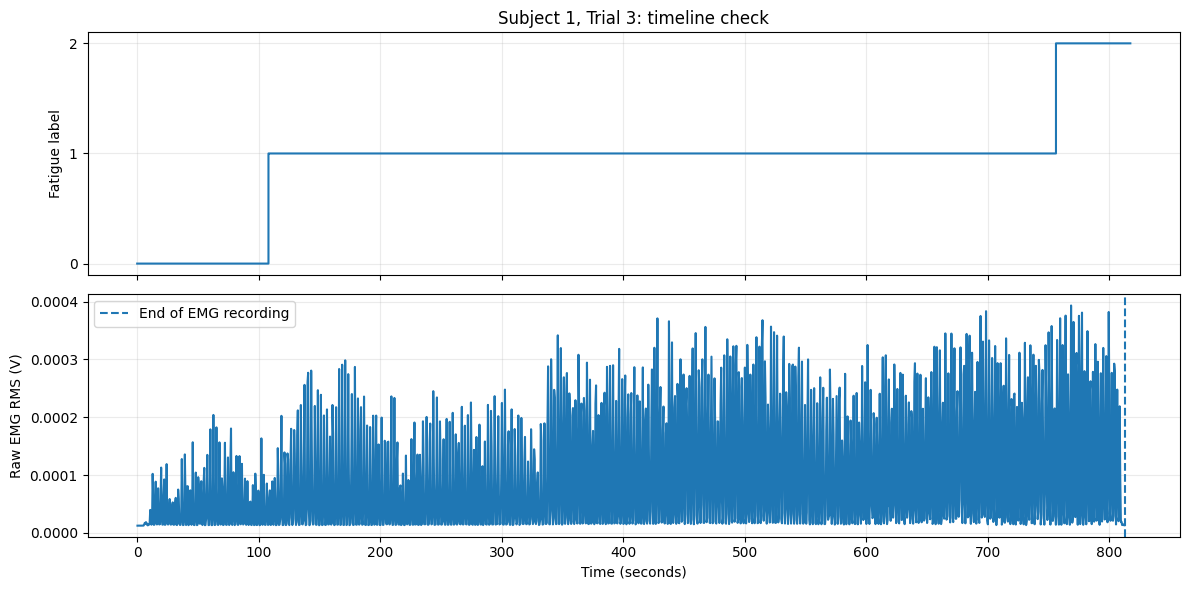


Subject 1, trial 3
EMG time range: 0.000–812.961 s
Label time range: 0.019–817.540 s
First label transitions (seconds): [108.08 756.32]
Saved: /content/drive/MyDrive/EMG_Project/analysis_outputs/plots/timeline_subject_1_trial_3.png


In [ ]:

# CELL 11: INSPECT EMG AND FATIGUE-LABEL TIMELINES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PLOTS_DIR = Path(
    "/content/drive/MyDrive/EMG_Project/"
    "analysis_outputs/plots"
)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

def inspect_trial_timeline(subject, trial):
    emg_folder = subject_folder(EMG_ROOT, subject)
    label_folder = subject_folder(LABEL_ROOT, subject)

    emg_matches = [
        p for p in get_csv_files(emg_folder)
        if trial_number(p.name) == trial
    ]
    label_matches = [
        p for p in get_csv_files(label_folder)
        if trial_number(p.name) == trial
    ]

    if not emg_matches or not label_matches:
        print(f"Files not found: subject {subject}, trial {trial}")
        return

    emg = pd.read_csv(emg_matches[0])
    labels = pd.read_csv(label_matches[0])

    # Select the same muscle channel used during feature extraction.
    channel = PRIME_MOVER_INDEX[trial]
    time_col = TIME_INDEX[channel]
    signal_col = EMG_INDEX[channel]

    emg_time = pd.to_numeric(
        emg.iloc[:, time_col], errors="coerce"
    ).to_numpy()
    emg_signal = pd.to_numeric(
        emg.iloc[:, signal_col], errors="coerce"
    ).to_numpy()

    label_time = pd.to_numeric(
        labels.iloc[:, 0], errors="coerce"
    ).to_numpy()
    label_values = pd.to_numeric(
        labels.iloc[:, 1], errors="coerce"
    ).to_numpy()

    valid_emg = np.isfinite(emg_time) & np.isfinite(emg_signal)
    valid_labels = np.isfinite(label_time) & np.isfinite(label_values)

    emg_time, emg_signal = emg_time[valid_emg], emg_signal[valid_emg]
    label_time, label_values = label_time[valid_labels], label_values[valid_labels]

    emg_order = np.argsort(emg_time)
    label_order = np.argsort(label_time)
    emg_time, emg_signal = emg_time[emg_order], emg_signal[emg_order]
    label_time, label_values = label_time[label_order], label_values[label_order]

    # Calculate RMS in half-second bins to make the plot readable.
    bin_width = 0.5
    bin_edges = np.arange(
        emg_time.min(), emg_time.max() + bin_width, bin_width
    )
    centers, rms_values = [], []

    for left, right in zip(bin_edges[:-1], bin_edges[1:]):
        mask = (emg_time >= left) & (emg_time < right)
        if mask.any():
            centers.append((left + right) / 2)
            rms_values.append(np.sqrt(np.mean(emg_signal[mask] ** 2)))

    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

    axes[0].step(
        label_time, label_values, where="post"
    )
    axes[0].set_ylabel("Fatigue label")
    axes[0].set_yticks([0, 1, 2])
    axes[0].set_title(
        f"Subject {subject}, Trial {trial}: timeline check"
    )
    axes[0].grid(alpha=0.25)

    axes[1].plot(centers, rms_values)
    axes[1].set_xlabel("Time (seconds)")
    axes[1].set_ylabel("Raw EMG RMS (V)")
    axes[1].grid(alpha=0.25)

    axes[1].axvline(
        emg_time.max(), linestyle="--",
        label="End of EMG recording"
    )
    axes[1].legend()

    fig.tight_layout()
    save_path = PLOTS_DIR / f"timeline_subject_{subject}_trial_{trial}.png"
    fig.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    changes = np.where(np.diff(label_values) != 0)[0] + 1

    print(f"\nSubject {subject}, trial {trial}")
    print(f"EMG time range: {emg_time.min():.3f}–{emg_time.max():.3f} s")
    print(f"Label time range: {label_time.min():.3f}–{label_time.max():.3f} s")
    print("First label transitions (seconds):",
          np.round(label_time[changes[:10]], 2))
    print("Saved:", save_path)

inspect_trial_timeline(1, 1)
inspect_trial_timeline(1, 3)


#Data Cleaning of Discrepancies

In [ ]:

from pathlib import Path
import pandas as pd
import re

# Change this if your dataset is stored somewhere else.
# Common Colab locations: /content or /content/drive/MyDrive
DATA_ROOT = Path("/content")

SUSPECTS = [
    (12, 3),
    (6, 5),
]

def normalize_name(path):
    return re.sub(r"[^a-z0-9]", "", str(path).lower())

def find_candidates(root, subject, trial):
    """
    Find CSV paths whose filenames or parent-folder names
    appear to identify the requested subject and trial.
    Prints candidates only; does not read or modify files.
    """
    candidates = []

    subject_patterns = [
        rf"subject[_ -]?0*{subject}(?!\d)",
        rf"sub[_ -]?0*{subject}(?!\d)",
        rf"^s0*{subject}(?!\d)",
    ]
    trial_patterns = [
        rf"trial[_ -]?0*{trial}(?!\d)",
        rf"task[_ -]?0*{trial}(?!\d)",
        rf"^t0*{trial}(?!\d)",
    ]

    for path in root.rglob("*.csv"):
        text = str(path).lower()
        name = path.stem.lower()

        subject_match = any(
            re.search(p, text) for p in subject_patterns
        )
        trial_match = any(
            re.search(p, name) for p in trial_patterns
        )

        if subject_match and trial_match:
            candidates.append(path)

    return sorted(set(candidates))


print("Dataset root:", DATA_ROOT)
if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"{DATA_ROOT} does not exist. Update DATA_ROOT."
    )

for subject, trial in SUSPECTS:
    print(f"\n{'=' * 65}")
    print(f"SUBJECT {subject}, TRIAL {trial}")
    print("=" * 65)

    matches = find_candidates(DATA_ROOT, subject, trial)

    if not matches:
        print("No matching CSV filenames found.")
        print("Your dataset may use different naming conventions.")
        continue

    for path in matches:
        print(f"\nCandidate: {path}")
        print(f"File size: {path.stat().st_size:,} bytes")

        try:
            # Read only enough rows to inspect structure.
            sample = pd.read_csv(path, nrows=5)
            print("Columns:", sample.columns.tolist())
            print("First 5 rows:")
            print(sample.to_string(index=False))

            # Count rows without loading the full file into memory.
            with path.open("rb") as f:
                row_count = sum(1 for _ in f) - 1

            print("Approximate data rows:", row_count)

        except Exception as exc:
            print("Could not inspect this file:", repr(exc))


Dataset root: /content

SUBJECT 12, TRIAL 3

Candidate: /content/semg_fatigue_work/emg/sEMG_data/subject_12/trial_3.csv
File size: 22,619,502 bytes
Columns: ['X [s]', 'R BICEPS BRACHII: EMG 1 [V]', 'X [s].1', 'R DELTOID ANTERIOR: EMG 2 [V]', 'X [s].5', 'R DELTOID MEDIUS: EMG 6 [V]', 'X [s].6', 'R DELTOID POSTERIOR: EMG 7 [V]']
First 5 rows:
   X [s]  R BICEPS BRACHII: EMG 1 [V]  X [s].1  R DELTOID ANTERIOR: EMG 2 [V]  X [s].5  R DELTOID MEDIUS: EMG 6 [V]  X [s].6  R DELTOID POSTERIOR: EMG 7 [V]
0.000000                    -0.000006 0.000000                      -0.000023 0.000000                    -0.000008 0.000000                       -0.000029
0.000794                    -0.000004 0.000794                      -0.000023 0.000794                    -0.000008 0.000794                       -0.000028
0.001588                    -0.000008 0.001588                      -0.000025 0.001588                    -0.000003 0.001588                       -0.000027
0.002382                    -

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/semg_fatigue_work")

TRIALS = [
    {
        "subject": 12,
        "trial": 3,
        "emg": ROOT / "emg/sEMG_data/subject_12/trial_3.csv",
        "labels": ROOT / "labels/self_perceived_fatigue_index/subject_12/trial_3.csv",
    },
    {
        "subject": 6,
        "trial": 5,
        "emg": ROOT / "emg/sEMG_data/subject_6/trial_5.csv",
        "labels": ROOT / "labels/self_perceived_fatigue_index/subject_6/trial_5.csv",
    },
]

def summarize_time(series):
    """Summarize a timestamp column without assuming its units."""
    t = pd.to_numeric(series, errors="coerce").dropna().to_numpy()

    if len(t) < 2:
        print("  Not enough valid timestamps.")
        return

    dt = np.diff(t)
    positive_dt = dt[dt > 0]

    print(f"  Valid timestamps: {len(t):,}")
    print(f"  First timestamp:  {t[0]:.6f}")
    print(f"  Last timestamp:   {t[-1]:.6f}")
    print(f"  Last - first:     {t[-1] - t[0]:.6f} seconds")

    print(f"  Non-increasing intervals: {(dt <= 0).sum():,}")
    print(f"  Negative intervals:       {(dt < 0).sum():,}")

    if len(positive_dt):
        print(f"  Median positive interval: {np.median(positive_dt):.8f} s")
        print(f"  Mean positive interval:   {np.mean(positive_dt):.8f} s")
        print(f"  Approx. rate from median interval: "
              f"{1 / np.median(positive_dt):.3f} Hz")

        print("  Interval quantiles (s):",
              np.quantile(positive_dt, [0, .25, .5, .75, .99, 1]).round(8))

for item in TRIALS:
    print("\n" + "=" * 72)
    print(f"SUBJECT {item['subject']} — TRIAL {item['trial']}")
    print("=" * 72)

    for kind in ("emg", "labels"):
        path = item[kind]
        print(f"\n[{kind.upper()}] {path}")

        if not path.exists():
            print("FILE NOT FOUND")
            continue

        df = pd.read_csv(path)
        print(f"Rows: {len(df):,}")
        print("Columns:", df.columns.tolist())

        if kind == "emg":
            time_cols = [
                c for c in df.columns
                if str(c).strip().lower().startswith("x [s]")
            ]

            print("EMG timestamp columns:", time_cols)

            for col in time_cols:
                print(f"\n  Timestamp column: {col}")
                summarize_time(df[col])

            # Show final values from the first timestamp and signal channel.
            print("\nLast 5 rows (first timestamp + first EMG channel):")
            print(df.iloc[-5:, :2].to_string(index=False))

        else:
            if "time" not in df.columns or "label" not in df.columns:
                print("Expected 'time' and 'label' columns were not found.")
                continue

            print("\nLabel timeline:")
            summarize_time(df["time"])

            labels = pd.to_numeric(df["label"], errors="coerce")
            print("\nLabel counts, including missing values:")
            print(df["label"].value_counts(dropna=False).sort_index().to_string())

            print("\nInvalid/missing numeric labels:", labels.isna().sum())
            print("Label transitions:", (labels != labels.shift()).sum() - 1)

            # Show label changes with their original timestamps.
            changed = labels.ne(labels.shift()) & labels.notna()
            print("\nFirst 10 label transitions:")
            print(df.loc[changed, ["time", "label"]].head(10).to_string(index=False))

            print("\nLast 10 label transitions:")
            print(df.loc[changed, ["time", "label"]].tail(10).to_string(index=False))

    # Compare endpoint durations using the first EMG timestamp column.
    emg = pd.read_csv(item["emg"])
    lab = pd.read_csv(item["labels"])

    emg_time_cols = [
        c for c in emg.columns
        if str(c).strip().lower().startswith("x [s]")
    ]

    if emg_time_cols and "time" in lab.columns:
        et = pd.to_numeric(emg[emg_time_cols[0]], errors="coerce").dropna()
        lt = pd.to_numeric(lab["time"], errors="coerce").dropna()

        if len(et) and len(lt):
            print("\n[ENDPOINT COMPARISON]")
            print(f"EMG:    {et.iloc[0]:.6f} to {et.iloc[-1]:.6f} s")
            print(f"Labels: {lt.iloc[0]:.6f} to {lt.iloc[-1]:.6f} s")
            print(f"Label endpoint minus EMG endpoint: "
                  f"{lt.iloc[-1] - et.iloc[-1]:.6f} s")



SUBJECT 12 — TRIAL 3

[EMG] /content/semg_fatigue_work/emg/sEMG_data/subject_12/trial_3.csv
Rows: 139,315
Columns: ['X [s]', 'R BICEPS BRACHII: EMG 1 [V]', 'X [s].1', 'R DELTOID ANTERIOR: EMG 2 [V]', 'X [s].5', 'R DELTOID MEDIUS: EMG 6 [V]', 'X [s].6', 'R DELTOID POSTERIOR: EMG 7 [V]']
EMG timestamp columns: ['X [s]', 'X [s].1', 'X [s].5', 'X [s].6']

  Timestamp column: X [s]
  Valid timestamps: 139,315
  First timestamp:  0.000000
  Last timestamp:   110.631641
  Last - first:     110.631641 seconds
  Non-increasing intervals: 0
  Negative intervals:       0
  Median positive interval: 0.00079412 s
  Mean positive interval:   0.00079412 s
  Approx. rate from median interval: 1259.260 Hz
  Interval quantiles (s): [0.00079412 0.00079412 0.00079412 0.00079412 0.00079412 0.00079412]

  Timestamp column: X [s].1
  Valid timestamps: 139,315
  First timestamp:  0.000000
  Last timestamp:   0.000000
  Last - first:     0.000000 seconds
  Non-increasing intervals: 1
  Negative intervals:    

In [ ]:

from pathlib import Path
import re

PROJECT = Path("/content/semg_fatigue_work")

patterns = re.compile(
    r"read_csv|label|timestamp|sampling|resample|"
    r"window|segment|duration|merge|join|searchsorted|"
    r"feature|subject|trial",
    re.IGNORECASE
)

for path in sorted(PROJECT.rglob("*.py")):
    # Skip common generated or dependency folders.
    if any(part in {".git", "__pycache__", "venv", ".venv"}
           for part in path.parts):
        continue

    try:
        lines = path.read_text(errors="replace").splitlines()
    except OSError:
        continue

    matching = [
        (i, line.strip())
        for i, line in enumerate(lines, start=1)
        if patterns.search(line)
    ]

    if matching:
        print(f"\n{'=' * 70}\nFILE: {path}")
        for line_no, line in matching[:45]:
            print(f"{line_no:4}: {line[:220]}")

        if len(matching) > 45:
            print(f"... {len(matching) - 45} additional matching lines omitted")


In [ ]:
from pathlib import Path

PROJECT = Path("/content/semg_fatigue_work")

print("Project folder exists:", PROJECT.exists())

if PROJECT.exists():
    print("\nTop-level contents:")
    for item in sorted(PROJECT.iterdir()):
        kind = "DIR " if item.is_dir() else "FILE"
        print(f"{kind} {item.name}")

    print("\nCode/notebook files found:")
    code_files = [
        p for p in PROJECT.rglob("*")
        if p.is_file()
        and p.suffix.lower() in {".py", ".ipynb", ".txt"}
        and not any(
            part in {".git", "__pycache__", "venv", ".venv"}
            for part in p.parts
        )
    ]

    if code_files:
        for p in code_files[:100]:
            print(p)
        if len(code_files) > 100:
            print(f"... {len(code_files) - 100} more files")
    else:
        print("No Python, notebook, or text files found.")
else:
    print("The expected project path does not exist.")

Project folder exists: True

Top-level contents:
DIR  emg
DIR  labels

Code/notebook files found:
/content/semg_fatigue_work/labels/_extraction_complete.txt
/content/semg_fatigue_work/emg/_extraction_complete.txt


In [ ]:

import json
from pathlib import Path

nb_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/EMG_Project.ipynb"
)

with nb_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "read_csv", "label", "timestamp", "sampling_rate",
    "window", "segment", "resample", "merge", "join",
    "feature", "duration", "fatigue", "train_test_split",
    "to_csv", "searchsorted"
]

print("Notebook:", nb_path.name)
print("Total cells:", len(notebook.get("cells", [])))

for i, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    if not source.strip():
        continue

    matched_lines = [
        (line_no, line)
        for line_no, line in enumerate(source.splitlines(), 1)
        if any(k in line.lower() for k in keywords)
    ]

    if matched_lines:
        print(f"\n{'=' * 65}")
        print(f"CELL {i}")
        for line_no, line in matched_lines[:35]:
            print(f"{line_no:3}: {line[:220]}")
        if len(matched_lines) > 35:
            print("... additional matching lines omitted")


Notebook: EMG_Project.ipynb
Total cells: 33

CELL 2
 26: LABEL_ZIP = PROJECT_DIR / "self_perceived_fatigue_index.zip"
 39: print("Fatigue-label ZIP exists:", LABEL_ZIP.exists())
 42: if not EMG_ZIP.exists() or not LABEL_ZIP.exists():

CELL 4
  1: WORK_DIR = Path("/content/semg_fatigue_work")
  3: LABEL_EXTRACT_DIR = WORK_DIR / "labels"
 34: extract_zip_if_needed(LABEL_ZIP, LABEL_EXTRACT_DIR)
 53: LABEL_ROOT = find_subject_root(LABEL_EXTRACT_DIR)
 56: print("Label root:", LABEL_ROOT)
 64: print("\nLabel subject folders:")
 66:     [p.name for p in LABEL_ROOT.iterdir()

CELL 6
 41:     label_folder = subject_folder(LABEL_ROOT, subject)
 44:     label_files = get_csv_files(label_folder)
 47:     label_by_trial = {}
 54:     for path in label_files:
 57:             label_by_trial.setdefault(tid, []).append(path)
 60:         set(emg_by_trial) & set(label_by_trial)
 66:         if len(emg_by_trial[tid]) == 1 and len(label_by_trial[tid]) == 1:
 70:                 "label_path": label_by_tri

In [ ]:

import json
from pathlib import Path

p = Path("/content/drive/MyDrive/Colab Notebooks/EMG_Project.ipynb")
nb = json.loads(p.read_text())

for i, cell in enumerate(nb["cells"]):
    src = "".join(cell.get("source", []))
    if "def label_window" in src:
        print(f"Found label-processing code in notebook cell {i}")
        print("=" * 70)
        print(src)
        break
else:
    print("Could not find label_window; searching for the feature-building loop.")
    for i, cell in enumerate(nb["cells"]):
        src = "".join(cell.get("source", []))
        if "feature_rows = []" in src:
            print(f"Found feature-building code in notebook cell {i}")
            print("=" * 70)
            print(src)
            break


Found label-processing code in notebook cell 14
def load_numeric_column(df, column_index):
    """Convert a CSV column to numeric values."""
    return pd.to_numeric(
        df.iloc[:, column_index],
        errors="coerce"
    ).to_numpy(dtype=float)


def label_window(label_times, label_values, start_time, end_time):
    """
    Assign the majority fatigue label within a window.
    Also return label purity and whether labels were mixed.
    """
    inside = (
        np.isfinite(label_times) &
        np.isfinite(label_values) &
        (label_times >= start_time) &
        (label_times <= end_time)
    )

    values = label_values[inside].astype(int)

    if len(values) == 0:
        # Fallback if no rating timestamp falls inside the window.
        valid = (
            np.isfinite(label_times) &
            np.isfinite(label_values)
        )

        if not valid.any():
            return None, np.nan, True

        valid_times = label_times[valid]
        valid_values = label_

In [ ]:
import pandas as pd
from pathlib import Path

base = Path("/content/semg_fatigue_work")

suspects = [
    {
        "subject": 12,
        "trial": 3,
        "emg_duration_s": 110.631641,
        "label_path": base / "labels/self_perceived_fatigue_index/subject_12/trial_3.csv",
    },
    {
        "subject": 6,
        "trial": 5,
        "emg_duration_s": 24.524721,
        "label_path": base / "labels/self_perceived_fatigue_index/subject_6/trial_5.csv",
    },
]

for item in suspects:
    subject = item["subject"]
    trial = item["trial"]
    emg_end = item["emg_duration_s"]

    print(f"\n{'=' * 60}")
    print(f"Subject {subject}, Trial {trial}")
    print(f"EMG ends at: {emg_end:.3f} seconds")

    labels = pd.read_csv(item["label_path"])
    times = pd.to_numeric(labels.iloc[:, 0], errors="coerce")
    values = pd.to_numeric(labels.iloc[:, 1], errors="coerce")

    valid = times.notna() & values.notna()
    labels = pd.DataFrame({
        "time": times[valid],
        "label": values[valid].astype(int),
    }).sort_values("time")

    overlapping = labels[
        (labels["time"] >= 0) &
        (labels["time"] <= emg_end)
    ]

    print(f"Label timestamps inside EMG time range: {len(overlapping)}")
    print("Labels inside EMG range:")
    print(overlapping["label"].value_counts().sort_index().to_dict())

    print("\nFull label timeline:")
    print(labels["label"].value_counts().sort_index().to_dict())

    print("\nFirst and last label timestamp:")
    print(labels["time"].min(), labels["time"].max())

    print("\nLabel transitions:")
    changed = labels["label"].ne(labels["label"].shift())
    print(labels.loc[changed, ["time", "label"]].to_string(index=False))

    if "feature_df" in globals() and not feature_df.empty:
        rows = feature_df[
            (feature_df["subject"] == subject) &
            (feature_df["trial"] == trial)
        ]

        print("\nLabels actually assigned by the pipeline:")
        print(rows["fatigue_label"].value_counts().sort_index().to_dict())
        print("Feature windows:", len(rows))
        if not rows.empty:
            print(
                "Feature window time range:",
                rows["window_start_s"].min(),
                "to",
                rows["window_end_s"].max(),
            )


Subject 12, Trial 3
EMG ends at: 110.632 seconds
Label timestamps inside EMG time range: 5531
Labels inside EMG range:
{0: 5531}

Full label timeline:
{0: 7399, 1: 6776, 2: 15123}

First and last label timestamp:
0.021 585.96099

Label transitions:
     time  label
  0.02100      0
148.00000      1
283.51998      2

Labels actually assigned by the pipeline:
{0: 54}
Feature windows: 54
Feature window time range: 0.0 to 110.01937645919033

Subject 6, Trial 5
EMG ends at: 24.525 seconds
Label timestamps inside EMG time range: 1226
Labels inside EMG range:
{0: 1226}

Full label timeline:
{0: 11074, 1: 4172, 2: 3624}

First and last label timestamp:
0.021 377.401

Label transitions:
   time  label
  0.021      0
221.501      1
304.940      2

Labels actually assigned by the pipeline:
{0: 11}
Feature windows: 11
Feature window time range: 0.0 to 24.00298588059654


In [ ]:
from pathlib import Path
import pandas as pd
import zipfile

# 1. Find the duration audit generated by your notebook.
search_roots = [
    Path("/content/drive/MyDrive/EMG_Project"),
    Path("/content/semg_fatigue_work"),
]

audit_files = [
    p for root in search_roots if root.exists()
    for p in root.rglob("duration_audit.csv")
]

print("DURATION AUDIT")
if not audit_files:
    print("duration_audit.csv not found in the searched folders.")
else:
    for path in audit_files:
        print(f"\nFile: {path}")
        df = pd.read_csv(path)
        print("Columns:", df.columns.tolist())
        print(df.to_string(index=False, max_rows=8))

        # Print useful numeric summaries without assuming exact column names.
        numeric_cols = df.select_dtypes(include="number").columns
        print("\nNumeric summary:")
        print(df[numeric_cols].describe().round(2).to_string())

# 2. Find documentation files in the project and extracted dataset.
print("\n\nDATASET DOCUMENTATION FILES")
for root in search_roots:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and any(
                word in p.name.lower()
                for word in ["metadata", "protocol", "readme", "code.ipynb"]
            ):
                print(p)

# 3. List documentation-like files inside the original archives.
print("\n\nARCHIVE CONTENTS")
for zip_path in Path("/content/drive/MyDrive/EMG_Project").glob("*.zip"):
    print(f"\n{zip_path.name}")
    try:
        with zipfile.ZipFile(zip_path) as z:
            matches = [
                name for name in z.namelist()
                if any(word in name.lower() for word in [
                    "metadata", "protocol", "readme", "code.ipynb"
                ])
            ]
            print("\n".join(matches[:40]) if matches else
                  "No documentation-like filenames found.")
    except Exception as e:
        print("Could not inspect archive:", e)

DURATION AUDIT

File: /content/drive/MyDrive/EMG_Project/analysis_outputs/tables/duration_audit.csv
Columns: ['subject', 'trial', 'emg_duration_s', 'label_duration_s', 'duration_difference_s']
 subject  trial  emg_duration_s  label_duration_s  duration_difference_s
       1      1       95.650620         105.80000              10.149380
       1      2      111.992758         115.04000               3.047242
       1      3      812.960786         817.52097               4.560184
       1      4      699.923765         702.50001               2.576245
     ...    ...             ...               ...                    ...
      13      9      802.377587         803.83998               1.462393
      13     10      766.547814         767.94002               1.392206
      13     11     1488.049331        1489.38102               1.331689
      13     12      273.260486         399.73900             126.478514

Numeric summary:
       subject   trial  emg_duration_s  label_duration_s  d

In [ ]:
import numpy as np
import pandas as pd

audit_rows = []

for subject, pairs in file_pairs.items():
    for pair in pairs:
        trial = pair["trial"]

        emg = pd.read_csv(pair["emg_path"])
        labels = pd.read_csv(pair["label_path"])

        # Use the first EMG timestamp column and label timestamp column.
        emg_t = pd.to_numeric(
            emg.iloc[:, 0], errors="coerce"
        ).dropna()

        label_t = pd.to_numeric(
            labels.iloc[:, 0], errors="coerce"
        )
        label_v = pd.to_numeric(
            labels.iloc[:, 1], errors="coerce"
        )

        valid = label_t.notna() & label_v.notna()
        label_t = label_t[valid].to_numpy(dtype=float)
        label_v = label_v[valid].to_numpy(dtype=int)

        if emg_t.empty or len(label_t) == 0:
            continue

        emg_start = float(emg_t.min())
        emg_end = float(emg_t.max())
        label_start = float(label_t.min())
        label_end = float(label_t.max())

        # Labels that fall within the EMG's recorded time span.
        inside = (
            (label_t >= emg_start) &
            (label_t <= emg_end)
        )
        inside_labels = label_v[inside]

        # Find every timestamp at which the reported class changes.
        order = np.argsort(label_t)
        sorted_t = label_t[order]
        sorted_v = label_v[order]
        changes = np.flatnonzero(sorted_v[1:] != sorted_v[:-1]) + 1
        transition_times = sorted_t[changes]

        transitions_after_emg = int(
            np.sum(transition_times > emg_end)
        )
        transitions_inside_emg = int(
            np.sum(
                (transition_times >= emg_start) &
                (transition_times <= emg_end)
            )
        )

        difference = label_end - emg_end

        audit_rows.append({
            "subject": subject,
            "trial": trial,
            "emg_duration_s": emg_end - emg_start,
            "label_duration_s": label_end - label_start,
            "duration_difference_s": difference,
            "label_coverage_pct": (
                100 * len(inside_labels) / len(label_t)
            ),
            "classes_inside_emg": (
                ",".join(map(str, sorted(set(inside_labels))))
                if len(inside_labels) else "none"
            ),
            "transitions_inside_emg": transitions_inside_emg,
            "transitions_after_emg": transitions_after_emg,
            "transition_times_s": np.round(
                transition_times, 2
            ).tolist(),
        })

audit_all = pd.DataFrame(audit_rows)

# Show trials with a large duration mismatch or no fatigue transition
# during the EMG recording.
suspects = audit_all[
    (audit_all["duration_difference_s"] > 5) |
    (audit_all["transitions_after_emg"] > 0)
].sort_values(
    "duration_difference_s", ascending=False
)

print("Matched trials audited:", len(audit_all))
print("Trials flagged for inspection:", len(suspects))
display(suspects.to_string(index=False))

print("\nLargest duration discrepancies:")
display(
    audit_all.nlargest(15, "duration_difference_s")
    .to_string(index=False)
)

Matched trials audited: 156
Trials flagged for inspection: 17


' subject  trial  emg_duration_s  label_duration_s  duration_difference_s  label_coverage_pct classes_inside_emg  transitions_inside_emg  transitions_after_emg transition_times_s\n      12      3      110.631641         585.93999             475.329349           18.878422                  0                       0                      2    [148.0, 283.52]\n       6      5       24.524721         377.38000             352.876279            6.497085                  0                       0                      2    [221.5, 304.94]\n       9     11      588.986389         860.10099             271.133601           68.476492                0,1                       1                      1   [448.38, 653.18]\n       8     12      610.476788         880.50001             270.043222           69.329487                0,1                       1                      1   [103.12, 702.96]\n      13     12      273.260486         399.73900             126.499514           68.351011            


Largest duration discrepancies:


' subject  trial  emg_duration_s  label_duration_s  duration_difference_s  label_coverage_pct classes_inside_emg  transitions_inside_emg  transitions_after_emg transition_times_s\n      12      3      110.631641         585.93999             475.329349           18.878422                  0                       0                      2    [148.0, 283.52]\n       6      5       24.524721         377.38000             352.876279            6.497085                  0                       0                      2    [221.5, 304.94]\n       9     11      588.986389         860.10099             271.133601           68.476492                0,1                       1                      1   [448.38, 653.18]\n       8     12      610.476788         880.50001             270.043222           69.329487                0,1                       1                      1   [103.12, 702.96]\n      13     12      273.260486         399.73900             126.499514           68.351011            

In [ ]:

from pathlib import Path
import requests
import pandas as pd
import json

# Keep downloaded documentation separate from project data.
doc_dir = Path(
    "/content/drive/MyDrive/EMG_Project/analysis_outputs/official_docs"
)
doc_dir.mkdir(parents=True, exist_ok=True)

base = "https://zenodo.org/records/14182446/files"
files = {
    "protocol.xlsx": f"{base}/protocol.xlsx?download=1",
    "Metadata.xlsx": f"{base}/Metadata.xlsx?download=1",
    "code.ipynb": f"{base}/code.ipynb?download=1",
}

for name, url in files.items():
    path = doc_dir / name

    if path.exists():
        print(f"Already downloaded: {name}")
        continue

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    # Basic check that the server returned the expected file type.
    if name.endswith(".xlsx") and not response.content.startswith(b"PK"):
        raise ValueError(
            f"{name}: response is not a recognizable XLSX file. "
            "Do not save or inspect it as an Excel workbook."
        )

    path.write_bytes(response.content)
    print(f"Downloaded {name}: {path.stat().st_size:,} bytes")


# Inspect workbook sheet names, dimensions, headers and sample rows.
for name in ["protocol.xlsx", "Metadata.xlsx"]:
    path = doc_dir / name
    print(f"\n{'=' * 20} {name} {'=' * 20}")

    workbook = pd.ExcelFile(path)
    print("Sheets:", workbook.sheet_names)

    for sheet in workbook.sheet_names:
        df = pd.read_excel(path, sheet_name=sheet, header=None)
        print(f"\nSheet: {sheet}")
        print("Shape:", df.shape)
        print(df.head(12).to_string(index=False, header=False))


# Inspect the authors' notebook source without executing it.
notebook_path = doc_dir / "code.ipynb"
notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

print("\n========== OFFICIAL NOTEBOOK: TIMING / ALIGNMENT ==========")
for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    relevant = [
        line for line in source.splitlines()
        if any(term in line.lower() for term in [
            "label_time", "raw_time", "gt_times",
            "nearest_idx", "normalize_time",
            "trigger", "resample", "interpol",
            "truncate", "duration", "sampling_rate"
        ])
    ]

    if relevant:
        print(f"\nCell {i}:")
        for line in relevant:
            print(line)


Downloaded protocol.xlsx: 1,094,424 bytes
Downloaded Metadata.xlsx: 10,910 bytes
Downloaded code.ipynb: 21,304 bytes

==================== protocol.xlsx ====================
Sheets: ['Folha1']

Sheet: Folha1
Shape: (28, 9)
NaN               NaN              NaN NaN                  NaN NaN NaN NaN                     NaN
NaN               NaN              NaN NaN                  NaN NaN NaN NaN                     NaN
NaN Trial Description              NaN NaN                  NaN NaN NaN NaN Uniarticular movements:
NaN               NaN              NaN NaN                  NaN NaN NaN NaN                     NaN
NaN             Trial    Movement Type NaN      Agonist muscle  NaN NaN NaN                     NaN
NaN                 1 uni-articular *  NaN   R DELTOID ANTERIOR NaN NaN NaN                     NaN
NaN                 2 uni-articular *  NaN   L DELTOID ANTERIOR NaN NaN NaN                     NaN
NaN                 3 uni-articular *  NaN  R DELTOID POSTERIOR NaN NaN NaN  

In [ ]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/EMG_Project/analysis_outputs/"
    "official_docs/code.ipynb"
)

nb = json.loads(path.read_text(encoding="utf-8"))

# Print the complete cells containing the time-normalization
# function and the label-transition mapping.
for i in [1, 3]:
    cell = nb["cells"][i]
    print(f"\n{'=' * 25} CELL {i} {'=' * 25}")
    print("".join(cell.get("source", [])))



========================= CELL 1 =========================
# Util functions

def plot_emg(time_data,emg_data,col_name):
    plt.figure(figsize=(10, 6))

    # Plot for raw data
    #plt.subplot(1, 2, 1)  # 1 row, 2 columns, first subplot
    plt.plot(time_data, emg_data, label="EMG Data", color='blue')
    plt.xlabel("Time (s)")
    plt.ylabel("EMG (V)")
    plt.title(str(col_name))
    plt.grid(True)

    # Display the plot

    #plt.tight_layout()
    plt.show()


def plot_emg_wlabels(x, y, name=None, label='Frequencies', gt_time=None):
    plt.figure(figsize=(12, 6))
    plt.plot(x, y)
    plt.title(str(label), fontsize=16) 
    plt.xlabel('Time (s)', fontsize=14)  
    plt.ylabel('Frequency (Hz)', fontsize=14)  
    plt.grid(True)
    plt.axvline(x=gt_time[0], color='black', linestyle='--', label='Non-Fatigue')
    plt.axvline(x=gt_time[1], color='black', linestyle='--', label='Transition-to-Fatigue')
    
    if name is not None:
        plt.savefig(name)
        print("saved at"

In [ ]:

from pathlib import Path
import re
import pandas as pd
import numpy as np

emg_root = Path("/content/semg_fatigue_work/emg/sEMG_data")
label_root = Path(
    "/content/semg_fatigue_work/labels/"
    "self_perceived_fatigue_index"
)

def list_trial_files(root, subject, trial):
    folder = root / f"subject_{subject}"
    if not folder.exists():
        print("Missing folder:", folder)
        return []

    results = []
    for path in sorted(folder.glob("*.csv")):
        nums = re.findall(r"\d+", path.stem)
        if nums and int(nums[-1]) == trial:
            results.append(path)

    return results

def summarize_csv(path, timestamp_columns, label_file=False):
    df = pd.read_csv(path)
    print(f"\nFile: {path.name}")
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))

    if label_file:
        t = pd.to_numeric(df.iloc[:, 0], errors="coerce")
        labels = pd.to_numeric(df.iloc[:, 1], errors="coerce")
        valid = t.notna()

        print("Timestamp first/last:", t[valid].iloc[0],
              t[valid].iloc[-1])
        print("Timestamp range (s):",
              t[valid].max() - t[valid].min())
        print("Monotonic increasing:", t[valid].is_monotonic_increasing)
        print("Label counts:", labels.value_counts(dropna=False).to_dict())
        print("First 5 rows:\n", df.head().to_string(index=False))
        print("Last 5 rows:\n", df.tail().to_string(index=False))
        return

    for idx in timestamp_columns:
        if idx >= df.shape[1]:
            print(f"Timestamp column index {idx} does not exist")
            continue

        t = pd.to_numeric(df.iloc[:, idx], errors="coerce").dropna()
        if t.empty:
            print(f"Column {idx}: no numeric timestamps")
            continue

        print(
            f"Column {idx} ({df.columns[idx]}): "
            f"first={t.iloc[0]}, last={t.iloc[-1]}, "
            f"duration={t.max() - t.min():.3f}s, "
            f"monotonic={t.is_monotonic_increasing}"
        )

    print("First 3 rows:\n", df.head(3).to_string(index=False))
    print("Last 3 rows:\n", df.tail(3).to_string(index=False))


for subject, trial in [(12, 3), (6, 5)]:
    print("\n" + "=" * 60)
    print(f"SUBJECT {subject}, TRIAL {trial}")

    emg_candidates = list_trial_files(emg_root, subject, trial)
    label_candidates = list_trial_files(label_root, subject, trial)

    print("EMG candidates:", [p.name for p in emg_candidates])
    print("Label candidates:", [p.name for p in label_candidates])

    if len(emg_candidates) != 1 or len(label_candidates) != 1:
        print("STOP: pairing is ambiguous; do not select files automatically.")
        continue

    summarize_csv(emg_candidates[0], [0, 2, 4, 6])
    summarize_csv(label_candidates[0], [], label_file=True)



SUBJECT 12, TRIAL 3
EMG candidates: ['trial_3.csv']
Label candidates: ['trial_3.csv']

File: trial_3.csv
Shape: (139315, 8)
Columns: ['X [s]', 'R BICEPS BRACHII: EMG 1 [V]', 'X [s].1', 'R DELTOID ANTERIOR: EMG 2 [V]', 'X [s].5', 'R DELTOID MEDIUS: EMG 6 [V]', 'X [s].6', 'R DELTOID POSTERIOR: EMG 7 [V]']
Column 0 (X [s]): first=0.0, last=110.63164080491715, duration=110.632s, monotonic=True
Column 2 (X [s].1): first=0.0, last=0.0, duration=110.631s, monotonic=False
Column 4 (X [s].5): first=0.0, last=110.63164080491715, duration=110.632s, monotonic=True
Column 6 (X [s].6): first=0.0, last=110.63164080491715, duration=110.632s, monotonic=True
First 3 rows:
    X [s]  R BICEPS BRACHII: EMG 1 [V]  X [s].1  R DELTOID ANTERIOR: EMG 2 [V]  X [s].5  R DELTOID MEDIUS: EMG 6 [V]  X [s].6  R DELTOID POSTERIOR: EMG 7 [V]
0.000000                    -0.000006 0.000000                      -0.000023 0.000000                    -0.000008 0.000000                       -0.000029
0.000794             


Subject 12, Trial 3
EMG interval: 0.000–110.632 s
Label interval: 0.021–585.961 s
Label samples inside EMG interval: 5531
Observed labels inside interval: {0: 5531}
Transitions (time, old label -> new label):
  148.000 s: 0 -> 1
  283.520 s: 1 -> 2


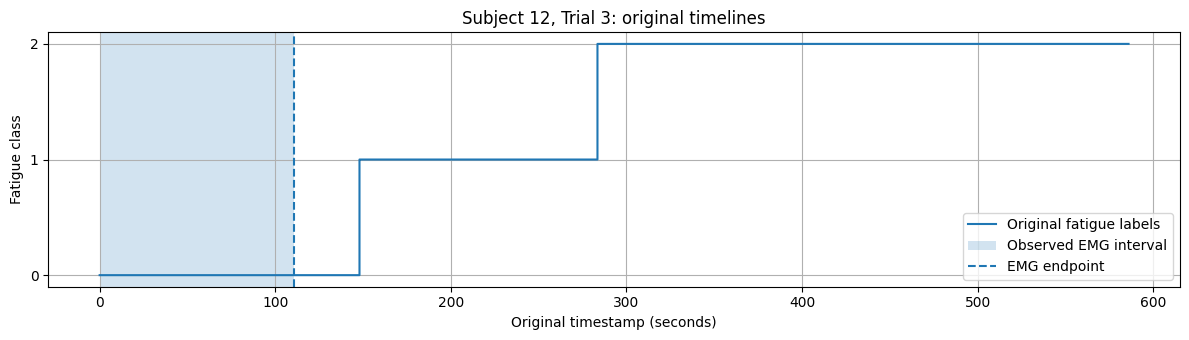


Subject 6, Trial 5
EMG interval: 0.000–24.525 s
Label interval: 0.021–377.401 s
Label samples inside EMG interval: 1226
Observed labels inside interval: {0: 1226}
Transitions (time, old label -> new label):
  221.501 s: 0 -> 1
  304.940 s: 1 -> 2


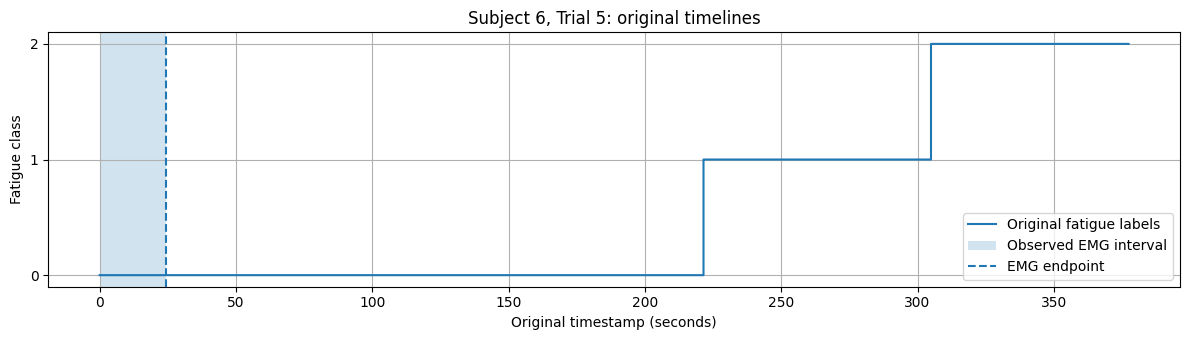

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

cases = [
    {
        "subject": 12,
        "trial": 3,
        "emg_col": 6,  # Selected channel's timestamp
    },
    {
        "subject": 6,
        "trial": 5,
        "emg_col": 0,  # Selected channel's timestamp
    },
]

for case in cases:
    subject, trial = case["subject"], case["trial"]

    emg_path = (
        Path("/content/semg_fatigue_work/emg/sEMG_data")
        / f"subject_{subject}" / f"trial_{trial}.csv"
    )
    label_path = (
        Path("/content/semg_fatigue_work/labels/"
             "self_perceived_fatigue_index")
        / f"subject_{subject}" / f"trial_{trial}.csv"
    )

    emg = pd.read_csv(emg_path)
    labels = pd.read_csv(label_path)

    et = pd.to_numeric(
        emg.iloc[:, case["emg_col"]], errors="coerce"
    ).dropna()

    lt = pd.to_numeric(labels["time"], errors="coerce")
    lv = pd.to_numeric(labels["label"], errors="coerce")

    valid = lt.notna() & lv.notna()
    lt, lv = lt[valid], lv[valid]

    e_start, e_end = et.iloc[0], et.iloc[-1]
    overlap = (lt >= e_start) & (lt <= e_end)

    transitions = np.flatnonzero(
        lv.to_numpy()[1:] != lv.to_numpy()[:-1]
    ) + 1

    print(f"\nSubject {subject}, Trial {trial}")
    print(f"EMG interval: {e_start:.3f}–{e_end:.3f} s")
    print(f"Label interval: {lt.iloc[0]:.3f}–{lt.iloc[-1]:.3f} s")
    print(f"Label samples inside EMG interval: {overlap.sum()}")
    print("Observed labels inside interval:",
          lv[overlap].value_counts().sort_index().to_dict())

    print("Transitions (time, old label -> new label):")
    for i in transitions:
        print(
            f"  {lt.iloc[i]:.3f} s: "
            f"{lv.iloc[i - 1]} -> {lv.iloc[i]}"
        )

    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.step(lt, lv, where="post", label="Original fatigue labels")
    ax.axvspan(e_start, e_end, alpha=0.2, label="Observed EMG interval")
    ax.axvline(e_end, linestyle="--", label="EMG endpoint")
    ax.set(
        title=f"Subject {subject}, Trial {trial}: original timelines",
        xlabel="Original timestamp (seconds)",
        ylabel="Fatigue class",
        yticks=[0, 1, 2],
    )
    ax.grid(True)
    ax.legend()
    plt.tight_layout()
    plt.show()


In [ ]:

# ================================================================
# FINAL READ-ONLY sEMG / FATIGUE-LABEL AUDIT
# ================================================================
# Audits original EMG and label CSVs without changing them.
# Does NOT modify label_window, regenerate features, or train a model.
#
# Outputs:
#   final_audit/trial_audit.csv
#   final_audit/transition_audit.csv
#   final_audit/window_coverage_audit.csv
#   final_audit/file_pairing_audit.csv
#   final_audit/final_audit_report.txt
#
# Expected paths are the ones already used in this project.
# ================================================================

from pathlib import Path
from collections import Counter
import re
import json
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ------------------------- CONFIGURATION -------------------------

PROJECT_ROOT = Path("/content/drive/MyDrive/EMG_Project")
EMG_ROOT = Path("/content/semg_fatigue_work/emg/sEMG_data")
LABEL_ROOT = Path(
    "/content/semg_fatigue_work/labels/self_perceived_fatigue_index"
)
EXISTING_DURATION_AUDIT = (
    PROJECT_ROOT / "analysis_outputs" / "tables" / "duration_audit.csv"
)
OFFICIAL_DOCS = PROJECT_ROOT / "analysis_outputs" / "official_docs"

OUTPUT_DIR = PROJECT_ROOT / "analysis_outputs" / "final_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_SUBJECTS = range(1, 14)
EXPECTED_TRIALS = range(1, 13)

EXPECTED_EMG_FS = 1259.0
EXPECTED_LABEL_FS = 50.0

WINDOW_SECONDS = 4.0
STEP_SECONDS = 2.0

# Mapping from the dataset's official notebook:
# trial number -> index of selected EMG signal among the four channels.
# EMG timestamp columns are [0, 2, 4, 6].
OFFICIAL_PRIME_MOVER_INDEX = {
    1: 1, 2: 0,
    3: 3, 4: 2,
    5: 0, 6: 1,
    7: 2, 8: 3,
    9: 1, 10: 0,
    11: 3, 12: 2,
}

# Set this to True only if you have verified that the current feature
# pipeline uses the official mapping above. The audit will still run if
# False, but the report will clearly mark the mapping as unverified.
MAPPING_CONFIRMED_FOR_CURRENT_PIPELINE = False

# ---------------------------------------------------------------

def parse_ids(path):
    """Extract subject/trial IDs from paths like subject_12/trial_3.csv."""
    text = str(path)
    sm = re.search(r"subject[_ -]?(\d+)", text, re.I)
    tm = re.search(r"trial[_ -]?(\d+)", Path(path).stem, re.I)
    if not sm or not tm:
        return None
    return int(sm.group(1)), int(tm.group(1))


def collect_csvs(root):
    if not root.exists():
        return []
    return sorted(
        [p for p in root.rglob("*.csv") if p.is_file()],
        key=lambda p: str(p).lower()
    )


def make_index(paths):
    index = {}
    unparsed = []
    for p in paths:
        ids = parse_ids(p)
        if ids is None:
            unparsed.append(str(p))
        else:
            index.setdefault(ids, []).append(p)
    return index, unparsed


def read_csv_safely(path):
    # Try normal CSV parsing first, then Python's more tolerant parser.
    try:
        return pd.read_csv(path, low_memory=False)
    except Exception:
        return pd.read_csv(path, engine="python", on_bad_lines="warn")


def numeric_column(series):
    return pd.to_numeric(series, errors="coerce").to_numpy(dtype=float)


def timestamp_stats(t):
    """Return timestamp quality metrics; no timestamp correction is applied."""
    t = np.asarray(t, dtype=float)
    finite = np.isfinite(t)
    tf = t[finite]

    result = {
        "n_samples": int(len(t)),
        "n_nonfinite": int((~finite).sum()),
        "n_duplicate_steps": 0,
        "n_backward_steps": 0,
        "strictly_increasing": False,
        "monotonic_non_decreasing": False,
        "start_s": np.nan,
        "end_s": np.nan,
        "duration_s": np.nan,
        "median_dt_s": np.nan,
        "estimated_fs_hz": np.nan,
        "n_nonpositive_dt": 0,
        "n_large_gaps": 0,
    }

    if len(tf) == 0:
        return result

    # Use original sequence only when all timestamps are finite.
    # Dropping nonfinite points could hide ordering problems.
    result["start_s"] = float(tf[0])
    result["end_s"] = float(tf[-1])
    result["duration_s"] = float(tf[-1] - tf[0])

    if len(t) != len(tf):
        return result

    dt = np.diff(t)
    result["n_duplicate_steps"] = int(np.sum(dt == 0))
    result["n_backward_steps"] = int(np.sum(dt < 0))
    result["n_nonpositive_dt"] = int(np.sum(dt <= 0))
    result["strictly_increasing"] = bool(np.all(dt > 0))
    result["monotonic_non_decreasing"] = bool(np.all(dt >= 0))

    positive = dt[dt > 0]
    if len(positive):
        med = float(np.median(positive))
        result["median_dt_s"] = med
        if med > 0:
            result["estimated_fs_hz"] = float(1.0 / med)
            result["n_large_gaps"] = int(np.sum(dt > max(5 * med, 0.1)))

    return result


def label_transition_rows(t, labels, subject, trial, emg_start, emg_end):
    rows = []
    t = np.asarray(t, dtype=float)
    labels = np.asarray(labels)

    if len(t) != len(labels) or len(t) < 2:
        return rows

    for i in range(1, len(labels)):
        if not (np.isfinite(t[i - 1]) and np.isfinite(t[i])):
            continue
        if labels[i] != labels[i - 1]:
            ts = float(t[i])
            rows.append({
                "subject": subject,
                "trial": trial,
                "transition_time_s": ts,
                "from_label": str(labels[i - 1]),
                "to_label": str(labels[i]),
                "inside_emg_interval": bool(
                    emg_start <= ts <= emg_end
                ) if np.isfinite(emg_start) and np.isfinite(emg_end) else False,
                "seconds_from_emg_end": (
                    float(ts - emg_end)
                    if np.isfinite(emg_end) else np.nan
                ),
            })
    return rows


def get_emg_timestamps(df, trial):
    """
    Use the timestamp column associated with the selected channel
    according to the official mapping. Never silently substitute another
    timestamp column if the selected one is invalid.
    """
    prime_index = OFFICIAL_PRIME_MOVER_INDEX.get(trial)
    if prime_index is None:
        return None, None, None, "no_mapping_for_trial"

    timestamp_col_index = 2 * prime_index

    if df.shape[1] <= timestamp_col_index:
        return (
            None, prime_index, timestamp_col_index,
            "selected_timestamp_column_missing"
        )

    t = numeric_column(df.iloc[:, timestamp_col_index])
    return t, prime_index, timestamp_col_index, "ok"


# ------------------------- FIND FILES ----------------------------

print("Locating source files...")

emg_files = collect_csvs(EMG_ROOT)
label_files = collect_csvs(LABEL_ROOT)

emg_index, emg_unparsed = make_index(emg_files)
label_index, label_unparsed = make_index(label_files)

print(f"EMG CSVs found:   {len(emg_files)}")
print(f"Label CSVs found: {len(label_files)}")
print(f"Output directory: {OUTPUT_DIR}")

if not EMG_ROOT.exists():
    raise FileNotFoundError(f"EMG directory not found: {EMG_ROOT}")
if not LABEL_ROOT.exists():
    raise FileNotFoundError(f"Label directory not found: {LABEL_ROOT}")

# Pairing audit includes every discovered key and all expected keys.
all_keys = set(emg_index) | set(label_index)
expected_keys = {
    (s, t) for s in EXPECTED_SUBJECTS for t in EXPECTED_TRIALS
}
all_keys |= expected_keys

pairing_rows = []
trial_pairs = []

for subject, trial in sorted(all_keys):
    emg_matches = emg_index.get((subject, trial), [])
    label_matches = label_index.get((subject, trial), [])

    if len(emg_matches) == 1 and len(label_matches) == 1:
        status = "unique_pair"
        trial_pairs.append(
            (subject, trial, emg_matches[0], label_matches[0])
        )
    elif len(emg_matches) == 0 and len(label_matches) == 0:
        status = "both_files_missing"
    elif len(emg_matches) == 0:
        status = "emg_missing"
    elif len(label_matches) == 0:
        status = "label_missing"
    else:
        status = "ambiguous_duplicate_files"

    pairing_rows.append({
        "subject": subject,
        "trial": trial,
        "expected_pair": (subject, trial) in expected_keys,
        "n_emg_matches": len(emg_matches),
        "n_label_matches": len(label_matches),
        "emg_paths": " ; ".join(map(str, emg_matches)),
        "label_paths": " ; ".join(map(str, label_matches)),
        "pairing_status": status,
    })

pairing_df = pd.DataFrame(pairing_rows)

# ------------------------- TRIAL AUDIT ---------------------------

trial_rows = []
transition_rows = []
window_rows = []

for n, (subject, trial, emg_path, label_path) in enumerate(
    trial_pairs, start=1
):
    if n == 1 or n % 20 == 0:
        print(f"Auditing unique pair {n}/{len(trial_pairs)}...")

    row = {
        "subject": subject,
        "trial": trial,
        "emg_path": str(emg_path),
        "label_path": str(label_path),
        "pairing_status": "unique_pair",
        "selected_mapping_source": "official_notebook_mapping",
        "mapping_confirmed_for_current_pipeline":
            MAPPING_CONFIRMED_FOR_CURRENT_PIPELINE,
    }

    try:
        emg_df = read_csv_safely(emg_path)
        label_df = read_csv_safely(label_path)

        row["emg_n_rows"] = len(emg_df)
        row["emg_n_columns"] = emg_df.shape[1]
        row["label_n_rows"] = len(label_df)
        row["label_n_columns"] = label_df.shape[1]

        # Selected EMG timestamp
        et, prime_idx, timestamp_col_idx, map_status = get_emg_timestamps(
            emg_df, trial
        )
        row["prime_mover_index"] = prime_idx
        row["selected_emg_timestamp_column_index_zero_based"] = (
            timestamp_col_idx
        )
        row["selected_emg_timestamp_column_name"] = (
            str(emg_df.columns[timestamp_col_idx])
            if timestamp_col_idx is not None
            and timestamp_col_idx < len(emg_df.columns)
            else None
        )
        row["selected_timestamp_mapping_status"] = map_status

        if et is None:
            raise ValueError(f"Could not select EMG timestamps: {map_status}")

        es = timestamp_stats(et)
        for k, v in es.items():
            row[f"emg_{k}"] = v

        # Also audit every available timestamp column for context.
        # These results do not override the selected-channel decision.
        all_emg_ts_summary = []
        for ci in [0, 2, 4, 6]:
            if ci < emg_df.shape[1]:
                ts = numeric_column(emg_df.iloc[:, ci])
                st = timestamp_stats(ts)
                all_emg_ts_summary.append({
                    "column_index": ci,
                    "column_name": str(emg_df.columns[ci]),
                    "start_s": st["start_s"],
                    "end_s": st["end_s"],
                    "duration_s": st["duration_s"],
                    "strictly_increasing": st["strictly_increasing"],
                    "n_nonfinite": st["n_nonfinite"],
                    "n_backward_steps": st["n_backward_steps"],
                })
        row["all_emg_timestamp_columns_json"] = json.dumps(
            all_emg_ts_summary
        )

        # Label CSV convention: first column = timestamp, second = label.
        if label_df.shape[1] < 2:
            raise ValueError("Label CSV has fewer than two columns")

        lt = numeric_column(label_df.iloc[:, 0])
        raw_label_values = label_df.iloc[:, 1]
        numeric_labels = pd.to_numeric(
            raw_label_values, errors="coerce"
        ).to_numpy(dtype=float)

        ls = timestamp_stats(lt)
        for k, v in ls.items():
            row[f"label_{k}"] = v

        valid_label_numeric = np.isfinite(numeric_labels)
        finite_time = np.isfinite(lt)
        usable = valid_label_numeric & finite_time

        valid_labels = numeric_labels[usable]
        valid_label_times = lt[usable]

        unexpected = sorted(
            set(valid_labels.tolist()) - {0.0, 1.0, 2.0}
        )
        row["n_non_numeric_labels"] = int(
            np.sum(~valid_label_numeric)
        )
        row["unexpected_label_values"] = json.dumps(unexpected)
        row["n_unexpected_label_values"] = int(
            sum(np.sum(valid_labels == x) for x in unexpected)
        )

        counts = Counter(valid_labels.tolist())
        for cls in [0, 1, 2]:
            row[f"label_count_{cls}_whole_file"] = int(counts.get(cls, 0))

        row["label_classes_whole_file"] = json.dumps(
            sorted(set(valid_labels.tolist()))
        )

        # Valid time bounds are derived from the selected EMG timestamps
        # and the original label timestamps. No shifting or rescaling.
        emg_time_valid = np.isfinite(et).all() and len(et) > 1
        label_time_valid = np.isfinite(lt).all() and len(lt) > 1

        if emg_time_valid:
            emg_start = float(et[0])
            emg_end = float(et[-1])
        else:
            emg_start = emg_end = np.nan

        if label_time_valid:
            label_start = float(lt[0])
            label_end = float(lt[-1])
        else:
            label_start = label_end = np.nan

        row["emg_start_s"] = emg_start
        row["emg_end_s"] = emg_end
        row["label_start_s"] = label_start
        row["label_end_s"] = label_end

        row["duration_difference_label_minus_emg_s"] = (
            float(ls["duration_s"] - es["duration_s"])
            if np.isfinite(ls["duration_s"])
            and np.isfinite(es["duration_s"]) else np.nan
        )

        if emg_time_valid and label_time_valid:
            overlap_start = max(emg_start, label_start)
            overlap_end = min(emg_end, label_end)
            overlap_duration = max(0.0, overlap_end - overlap_start)
            emg_duration = max(0.0, emg_end - emg_start)
            overlap_fraction = (
                overlap_duration / emg_duration
                if emg_duration > 0 else np.nan
            )
        else:
            overlap_start = overlap_end = overlap_duration = np.nan
            overlap_fraction = np.nan

        row["overlap_start_s"] = overlap_start
        row["overlap_end_s"] = overlap_end
        row["overlap_duration_s"] = overlap_duration
        row["overlap_fraction_of_emg_duration"] = overlap_fraction

        # Label observations within the actual EMG interval.
        if emg_time_valid:
            inside_emg = (
                usable & (lt >= emg_start) & (lt <= emg_end)
            )
            observed = numeric_labels[inside_emg]
            observed_counts = Counter(observed.tolist())
        else:
            inside_emg = np.zeros(len(lt), dtype=bool)
            observed = np.array([])
            observed_counts = Counter()

        row["label_samples_inside_emg_interval"] = int(inside_emg.sum())
        row["observed_classes_inside_emg"] = json.dumps(
            sorted(set(observed.tolist()))
        )
        row["n_observed_classes_inside_emg"] = len(
            set(observed.tolist())
        )
        for cls in [0, 1, 2]:
            row[f"label_count_{cls}_inside_emg"] = int(
                observed_counts.get(cls, 0)
            )
        observed_total = sum(observed_counts.values())
        for cls in [0, 1, 2]:
            row[f"label_fraction_{cls}_inside_emg"] = (
                observed_counts.get(cls, 0) / observed_total
                if observed_total else np.nan
            )

        # Count labels in the true overlap interval.
        if np.isfinite(overlap_start) and np.isfinite(overlap_end):
            inside_overlap = (
                usable & (lt >= overlap_start) & (lt <= overlap_end)
            )
        else:
            inside_overlap = np.zeros(len(lt), dtype=bool)

        row["label_samples_inside_overlap"] = int(inside_overlap.sum())

        # Actual transitions, based on consecutive valid rows in the
        # original label sequence. Keep order; do not smooth or rewrite.
        transition_rows.extend(label_transition_rows(
            lt, numeric_labels, subject, trial, emg_start, emg_end
        ))

        this_transitions = [
            r for r in transition_rows
            if r["subject"] == subject and r["trial"] == trial
        ]
        row["n_label_transitions_whole_file"] = len(this_transitions)
        row["n_transitions_inside_emg"] = sum(
            r["inside_emg_interval"] for r in this_transitions
        )
        row["transitions_json"] = json.dumps([
            {
                "time_s": r["transition_time_s"],
                "from": r["from_label"],
                "to": r["to_label"],
                "inside_emg": r["inside_emg_interval"],
                "seconds_from_emg_end": r["seconds_from_emg_end"],
            }
            for r in this_transitions
        ])

        # Window coverage audit: simulate the current window boundaries
        # and detect windows with no label samples. Do not assign labels.
        if emg_time_valid and emg_end >= emg_start:
            starts = np.arange(
                emg_start,
                max(emg_start, emg_end - WINDOW_SECONDS) + 1e-9,
                STEP_SECONDS
            )
            for ws in starts:
                we = ws + WINDOW_SECONDS
                if we > emg_end + 1e-9:
                    continue

                in_window = (
                    usable & (lt >= ws) & (lt <= we)
                )
                n_in_window = int(in_window.sum())

                # Diagnose what the existing whole-file nearest-label
                # fallback would do, without adopting that label.
                nearest_time = np.nan
                nearest_label = np.nan
                nearest_outside_emg = False

                if n_in_window == 0 and usable.any():
                    valid_indices = np.where(usable)[0]
                    nearest_pos = valid_indices[
                        np.argmin(np.abs(lt[valid_indices] - (ws + we) / 2))
                    ]
                    nearest_time = float(lt[nearest_pos])
                    nearest_label = float(numeric_labels[nearest_pos])
                    nearest_outside_emg = not (
                        emg_start <= nearest_time <= emg_end
                    )

                window_rows.append({
                    "subject": subject,
                    "trial": trial,
                    "window_start_s": float(ws),
                    "window_end_s": float(we),
                    "label_samples_in_window": n_in_window,
                    "has_label_observations": n_in_window > 0,
                    "would_use_nearest_fallback": n_in_window == 0,
                    "nearest_whole_file_label_time_s": nearest_time,
                    "nearest_whole_file_label_value": nearest_label,
                    "nearest_label_outside_emg_interval":
                        nearest_outside_emg,
                })

        # Explicit quality flags; no arbitrary duration-ratio correction.
        flags = []

        if not es["strictly_increasing"]:
            flags.append("selected_emg_timestamps_not_strictly_increasing")
        if es["n_nonfinite"] > 0:
            flags.append("selected_emg_timestamps_nonfinite")
        if es["n_backward_steps"] > 0:
            flags.append("selected_emg_timestamp_backward_jumps")
        if es["n_duplicate_steps"] > 0:
            flags.append("selected_emg_duplicate_timestamps")
        if not ls["strictly_increasing"]:
            flags.append("label_timestamps_not_strictly_increasing")
        if ls["n_nonfinite"] > 0:
            flags.append("label_timestamps_nonfinite")
        if unexpected:
            flags.append("unexpected_label_values")
        if row["label_samples_inside_emg_interval"] == 0:
            flags.append("no_label_samples_inside_emg_interval")
        elif row["n_observed_classes_inside_emg"] == 1:
            flags.append("single_class_observed_inside_emg")
        if row["n_transitions_inside_emg"] == 0:
            flags.append("no_observed_label_transition_inside_emg")
        if (
            np.isfinite(emg_end) and np.isfinite(label_end)
            and label_end > emg_end
        ):
            flags.append("label_stream_extends_after_emg")
        if (
            np.isfinite(overlap_fraction)
            and overlap_fraction < 0.999
        ):
            flags.append("label_timeline_does_not_cover_full_emg_duration")
        if not MAPPING_CONFIRMED_FOR_CURRENT_PIPELINE:
            flags.append("verify_selected_channel_mapping_against_pipeline")

        row["quality_flags"] = " | ".join(flags) if flags else "none"

        # Disposition is descriptive, not a claim of proven synchronization.
        if not emg_time_valid or not label_time_valid:
            disposition = "UNRESOLVED_INVALID_TIMESTAMPS"
        elif not es["strictly_increasing"] or not ls["strictly_increasing"]:
            disposition = "REVIEW_TIMESTAMP_ORDER"
        elif row["label_samples_inside_emg_interval"] == 0:
            disposition = "NO_LABEL_OBSERVATIONS_IN_EMG"
        elif row["n_observed_classes_inside_emg"] == 1:
            disposition = "PARTIAL_CLASS_COVERAGE_SINGLE_CLASS"
        elif row["n_transitions_inside_emg"] > 0:
            disposition = "TRANSITIONS_OBSERVED_ALIGNMENT_STILL_UNVERIFIED"
        else:
            disposition = "LABELS_OBSERVED_NO_TRANSITION_ALIGNMENT_UNVERIFIED"

        row["audit_disposition"] = disposition

    except Exception as exc:
        row["audit_error"] = f"{type(exc).__name__}: {exc}"
        row["quality_flags"] = "audit_exception"
        row["audit_disposition"] = "UNRESOLVED_AUDIT_ERROR"

    trial_rows.append(row)

# ---------------------- CREATE OUTPUT TABLES ---------------------

trial_df = pd.DataFrame(trial_rows)
transitions_df = pd.DataFrame(transition_rows)
windows_df = pd.DataFrame(window_rows)

# Mark pairings that could not be audited because they were missing or
# ambiguous. They remain in the pairing report rather than being guessed.
pairing_df.to_csv(OUTPUT_DIR / "file_pairing_audit.csv", index=False)
trial_df.to_csv(OUTPUT_DIR / "trial_audit.csv", index=False)
transitions_df.to_csv(OUTPUT_DIR / "transition_audit.csv", index=False)
windows_df.to_csv(OUTPUT_DIR / "window_coverage_audit.csv", index=False)

# ---------------------- SUMMARY AND DECISIONS --------------------

def safe_count(df, col, value):
    if col not in df.columns:
        return 0
    return int((df[col] == value).sum())


expected_unique_pairs = len([
    key for key in expected_keys
    if len(emg_index.get(key, [])) == 1
    and len(label_index.get(key, [])) == 1
])

missing_or_ambiguous = pairing_df[
    pairing_df["expected_pair"]
    & (pairing_df["pairing_status"] != "unique_pair")
]

disposition_counts = (
    trial_df["audit_disposition"].value_counts().to_dict()
    if not trial_df.empty else {}
)

n_windows = len(windows_df)
n_no_label_windows = (
    int((~windows_df["has_label_observations"]).sum())
    if n_windows else 0
)
n_fallback_outside = (
    int(windows_df["nearest_label_outside_emg_interval"].sum())
    if n_windows else 0
)

# Identify duration-audit outliers, if the earlier audit exists.
duration_audit_note = "Previous duration audit not found."
duration_audit_flagged = []

if EXISTING_DURATION_AUDIT.exists():
    try:
        old = pd.read_csv(EXISTING_DURATION_AUDIT)
        duration_audit_note = (
            f"Previous duration audit loaded: {len(old)} rows."
        )
        # Include a compact preview of any rows with a duration difference
        # column. This is contextual only; raw timestamps remain authoritative.
        possible_diff_cols = [
            c for c in old.columns
            if "diff" in c.lower() or "difference" in c.lower()
        ]
        duration_audit_note += (
            " Duration-difference columns: "
            + (", ".join(possible_diff_cols) if possible_diff_cols else "not identified")
        )
        duration_audit_flagged = old.head(20).to_dict(orient="records")
    except Exception as exc:
        duration_audit_note = f"Could not parse previous audit: {exc}"

report = []
report.append("FINAL sEMG / LABEL DATASET AUDIT")
report.append("=" * 72)
report.append("")
report.append("1. FILE INVENTORY")
report.append(f"EMG CSV files found: {len(emg_files)}")
report.append(f"Label CSV files found: {len(label_files)}")
report.append(f"Expected subject-trial pairs: {len(expected_keys)}")
report.append(f"Unique pairs available for raw audit: {len(trial_pairs)}")
report.append(f"Expected pairs missing or ambiguous: {len(missing_or_ambiguous)}")
report.append(f"EMG files with unrecognized filenames: {len(emg_unparsed)}")
report.append(f"Label files with unrecognized filenames: {len(label_unparsed)}")
report.append("")

if not missing_or_ambiguous.empty:
    report.append("Missing/ambiguous expected pairs:")
    for _, r in missing_or_ambiguous.iterrows():
        report.append(
            f"  S{int(r['subject'])} T{int(r['trial'])}: "
            f"{r['pairing_status']}"
        )
    report.append("")

report.append("2. SELECTED CHANNEL MAPPING")
report.append(
    "This audit used the official notebook's trial-to-prime-mover mapping."
)
report.append(
    "Confirmed to match the current feature pipeline: "
    f"{MAPPING_CONFIRMED_FOR_CURRENT_PIPELINE}"
)
report.append(
    "If this is False, verify the mapping against the actual feature-building "
    "code before treating selected-channel timestamp checks as final."
)
report.append("")

report.append("3. TRIAL DISPOSITIONS")
for disposition, count in sorted(disposition_counts.items()):
    report.append(f"{disposition}: {count}")
report.append("")

report.append("4. WINDOW COVERAGE / FALLBACK RISK")
report.append(f"Complete 4-second windows audited: {n_windows}")
report.append(f"Windows with no label samples: {n_no_label_windows}")
report.append(
    "No-label windows whose nearest whole-file label lies outside the EMG "
    f"recording interval: {n_fallback_outside}"
)
report.append(
    "These counts diagnose risk; they do not mean the fallback labels were "
    "definitely used in the existing feature table."
)
report.append("")

report.append("5. KNOWN EXTREME CASES")
for subject, trial in [(12, 3), (6, 5)]:
    match = trial_df[
        (trial_df["subject"] == subject)
        & (trial_df["trial"] == trial)
    ]
    if len(match):
        r = match.iloc[0]
        report.append(
            f"S{subject} T{trial}: EMG {r.get('emg_start_s', np.nan):.3f}–"
            f"{r.get('emg_end_s', np.nan):.3f}s; label "
            f"{r.get('label_start_s', np.nan):.3f}–"
            f"{r.get('label_end_s', np.nan):.3f}s; "
            f"classes inside EMG={r.get('observed_classes_inside_emg', 'unknown')}; "
            f"transitions inside EMG={r.get('n_transitions_inside_emg', 'unknown')}; "
            f"disposition={r.get('audit_disposition', 'unknown')}"
        )
    else:
        report.append(f"S{subject} T{trial}: no unique pair was audited.")
report.append("")

report.append("6. PRIOR DURATION AUDIT")
report.append(duration_audit_note)
report.append("")

report.append("7. INTERPRETATION AND LIMITATIONS")
report.append(
    "- A duration mismatch alone does not prove misalignment."
)
report.append(
    "- Overlapping timestamps and matching start times do not independently "
    "prove synchronization."
)
report.append(
    "- No transition inside an EMG interval means transitions outside that "
    "interval cannot be assigned to the available EMG."
)
report.append(
    "- Single-class recordings may still provide genuine examples of that "
    "class, but they cannot provide evidence for unobserved classes."
)
report.append(
    "- The nearest-label fallback is unsafe when it can draw a label from "
    "outside the EMG interval or from outside the current window."
)
report.append(
    "- This audit does not repair, rescale, shift, truncate, interpolate, "
    "or relabel any original data."
)
report.append(
    "- A successful audit of timestamps is not proof that all existing "
    "feature rows were labeled correctly."
)
report.append("")

report.append("8. OUTPUT FILES")
for filename in [
    "file_pairing_audit.csv",
    "trial_audit.csv",
    "transition_audit.csv",
    "window_coverage_audit.csv",
]:
    report.append(f"- {OUTPUT_DIR / filename}")

report_text = "\n".join(report)
(OUTPUT_DIR / "final_audit_report.txt").write_text(
    report_text, encoding="utf-8"
)

print("\n" + report_text)
print("\nAUDIT COMPLETE.")
print("Original EMG, label CSVs, and feature table were not modified.")
print(f"Open the output folder: {OUTPUT_DIR}")
